# Figure 2: Integrated Assay Results

This notebook generates all panels for Figure 2 of the VarChAMP manuscript.

**Panel Organization:**

**A. Basic Comparisons**
- A: Score distributions (P/LP vs B/LB) - Mann-Whitney U
- B: Assay orthogonality (UpSet plot)

**B. Structural Context Analysis** (Reorganized for clarity)
1. **Unbiased overall view**: Structural patterns across P/LP + B/LB combined
2. **P/LP-focused comparison**: Assay-specific structural sensitivity differences  
3. **Functional feature analysis**: PTM sites, signal peptides, localization signals
4. **Biological interpretation**: Why imaging is structure-agnostic for pathogenic variants

**C. Additional Stratifications**
- F: Secondary structure context
- G: Disease module stratification
- H: Inheritance mode patterns
- I: Within-gene mechanistic heterogeneity

**Key Finding Preview:**
- Overall: All assays show higher scores in buried/structured regions
- Within P/LP only: Imaging LOSES structural sensitivity (Dual-IPA and PPI retain it)
- Explanation: PTM sites enriched in disordered/exposed regions regulate localization

In [1]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact, mannwhitneyu
from statannotations.Annotator import Annotator
from itertools import combinations
import re
import sys
import warnings
import matplotlib as mpl
import matplotlib.font_manager as fm

warnings.filterwarnings('ignore')

# Import existing utilities from the repo
sys.path.insert(0, '../../1_allele_collection/2_analysis')
sys.path.insert(0, '../../2_individual_assay_results')

from plot_utils import palette_dict, clinvar_order_dict
from analyses_plot_utils import (
    plot_assay_scores,
    plot_assay_hit_fisher_test,
    plot_gene_level_summary
)

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)

plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "figure.dpi": 300
})

## Configuration and Palettes

In [2]:
# File paths
DATA_PATH = '../3_outputs/0_all_gene_variants_assayed_summary.tsv'
OUTPUT_DIR = '../4_manuscript_figures/figure2'

# ClinVar palette
clinvar_palette = palette_dict['clinvar_clnsig_clean']
clinvar_binary_palette = {'P/LP': '#CA7682', 'B/LB': '#1D7AAB'}

# Assay palette (Nature-friendly colors)
assay_palette = {'Dual-IPA': '#E69F00', 'Imaging': '#0072B2', 'PPI': '#009E73'}
assay_order = ['Dual-IPA', 'Imaging', 'PPI']

# Column name mapping
assay_score_cols = {'Dual-IPA': 'dualipa_score', 'Imaging': 'imaging_score', 'PPI': 'ppi_score'}
assay_hit_cols = {'Dual-IPA': 'dualipa_hit', 'Imaging': 'imaging_hit', 'PPI': 'ppi_hit'}
assay_score_name = {
    'dualipa_score': 'Abundance Change Score',
    'imaging_score': 'Imaging Phenotype Score',
    'ppi_score': 'PPI Perturbation Score'
}

# Structural thresholds with references
RSA_THRESHOLD = 0.25  # Miller et al. 1987, Rost & Sander 1994 (RSA < 0.25 = buried)
PLDDT_THRESHOLD = 70  # Jumper et al. 2021 (AlphaFold, pLDDT >= 70 = confident/structured)

# Binary structural palettes
rsa_palette = {'Buried': '#D55E00', 'Exposed': '#56B4E9'}
plddt_palette = {'Disordered': '#56B4E9', 'Structured': '#D55E00'}
ss_palette = {'H (helix)': '#CC79A7', 'B (undefined)': '#E69F00', 'C (loop/coil)': '#56B4E9'}
inheritance_palette = {'Dominant': '#CC79A7', 'Recessive': '#0072B2', 'X-linked': '#D55E00', 'Multiple': '#708090'}

## Load and Preprocess Data

In [3]:
# Load data
df = pl.read_csv(DATA_PATH, separator='\t', infer_schema_length=10000)

print(f"Total variants: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"Unique genes: {df['symbol'].n_unique()}")

Total variants: 1407
Total columns: 1035
Unique genes: 163


In [4]:
def classify_clinvar_binary(cs):
    """Classify ClinVar significance into P/LP, B/LB, or Other."""
    if cs is None:
        return 'Other'
    cs = str(cs)
    if 'benign' in cs.lower() and 'pathogenic' not in cs.lower() and 'conflicting' not in cs.lower():
        return 'BLB'
    elif 'pathogenic' in cs.lower() and 'benign' not in cs.lower() and 'conflicting' not in cs.lower():
        return 'PLP'
    else:
        return 'Other'


# Add derived columns
df = df.with_columns([
    # Binary ClinVar classification
    pl.col('clinvar_clnsig_clean').map_elements(
        classify_clinvar_binary, return_dtype=pl.Utf8
    ).alias('clin_binary'),
    
    # RSA binary (Miller et al. 1987, Rost & Sander 1994: RSA < 0.25 = buried)
    pl.when(pl.col('rsa') < RSA_THRESHOLD)
      .then(pl.lit('Buried'))
      .otherwise(pl.lit('Exposed'))
      .alias('rsa_binary'),
    
    # pLDDT binary (Jumper et al. 2021: pLDDT >= 70 = confident/structured)
    pl.when(pl.col('plddt') >= PLDDT_THRESHOLD)
      .then(pl.lit('Structured'))
      .otherwise(pl.lit('Disordered'))
      .alias('plddt_binary'),
    
    # Simplified inheritance pattern
    pl.col('inheritance_pattern').map_elements(
        lambda x: {
            'autosomal dominant': 'Dominant',
            'autosomal recessive': 'Recessive',
            'x-linked recessive': 'X-linked',
            'x-linked dominant': 'X-linked',
            'x-linked': 'X-linked',
            'multiple': 'Multiple'
        }.get(x, None) if x else None,
        return_dtype=pl.Utf8
    ).alias('inheritance_simple')
])

# Summary
print("\nClinVar binary distribution:")
print(df['clin_binary'].value_counts().sort('clin_binary'))


ClinVar binary distribution:
shape: (3, 2)
┌─────────────┬───────┐
│ clin_binary ┆ count │
│ ---         ┆ ---   │
│ str         ┆ u32   │
╞═════════════╪═══════╡
│ BLB         ┆ 159   │
│ Other       ┆ 580   │
│ PLP         ┆ 668   │
└─────────────┴───────┘


## Helper Functions

Consolidated statistical and plotting utilities for the analysis.

In [5]:
def compute_fisher_exact_stats(df, hit_col, group_col, group1, group2):
    """Compute Fisher's exact test statistics for hit enrichment between two groups."""
    df_filtered = df.filter(
        pl.col(hit_col).is_not_null() & 
        pl.col(group_col).is_in([group1, group2])
    )
    
    g1 = df_filtered.filter(pl.col(group_col) == group1)
    g2 = df_filtered.filter(pl.col(group_col) == group2)
    
    g1_hits = g1.filter(pl.col(hit_col)).height
    g1_total = g1.height
    g2_hits = g2.filter(pl.col(hit_col)).height
    g2_total = g2.height
    
    table = [[g1_hits, g1_total - g1_hits], [g2_hits, g2_total - g2_hits]]
    odds_ratio, p_value = fisher_exact(table, alternative='two-sided')
    
    return {
        'odds_ratio': odds_ratio, 'p_value': p_value,
        f'{group1}_rate': g1_hits / g1_total if g1_total > 0 else 0,
        f'{group2}_rate': g2_hits / g2_total if g2_total > 0 else 0,
        f'{group1}_n': g1_total, f'{group2}_n': g2_total,
        'contingency_table': np.array(table)
    }


def compute_mannwhitney_stats(df, score_col, group_col, group1, group2):
    """Compute Mann-Whitney U test statistics for score differences between two groups."""
    df_filtered = df.filter(
        pl.col(score_col).is_not_null() & 
        pl.col(group_col).is_in([group1, group2])
    )
    
    g1_scores = df_filtered.filter(pl.col(group_col) == group1)[score_col].to_numpy()
    g2_scores = df_filtered.filter(pl.col(group_col) == group2)[score_col].to_numpy()
    
    if len(g1_scores) == 0 or len(g2_scores) == 0:
        return None
    
    stat, p_value = mannwhitneyu(g1_scores, g2_scores, alternative='two-sided')
    n1, n2 = len(g1_scores), len(g2_scores)
    r = 1 - (2 * stat) / (n1 * n2)  # Effect size: rank-biserial correlation
    
    return {
        'U_statistic': stat, 'p_value': p_value, 'effect_size_r': r,
        f'{group1}_median': np.median(g1_scores), f'{group2}_median': np.median(g2_scores),
        f'{group1}_n': n1, f'{group2}_n': n2
    }


def format_pvalue(p, include_p=True):
    """Format p-value for display."""
    prefix = 'p ' if include_p else ''
    return f"{prefix}< 0.0001" if p < 0.0001 else (f"{prefix}= {p:.4f}" if p < 0.001 else f"{prefix}= {p:.3f}")


def get_significance_stars(p):
    """Return significance stars based on p-value."""
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'


def feature_enrichment_test(df, feature_col, struct_col, struct_groups):
    """
    Fisher's exact test for feature enrichment in structural categories.
    Returns dict with group counts formatted as 'hits/total (%)' and N values.
    """
    g1 = df.filter(pl.col(struct_col) == struct_groups[0])
    g2 = df.filter(pl.col(struct_col) == struct_groups[1])
    
    g1_has = g1.filter(pl.col(feature_col)).height
    g1_total = g1.height
    g2_has = g2.filter(pl.col(feature_col)).height
    g2_total = g2.height
    
    if g1_total > 0 and g2_total > 0:
        table = [[g1_has, g1_total - g1_has], [g2_has, g2_total - g2_has]]
        odds_ratio, pval = fisher_exact(table)
        return {
            f'{struct_groups[0]}': f'{g1_has}/{g1_total} ({g1_has/g1_total*100:.1f}%)',
            f'{struct_groups[1]}': f'{g2_has}/{g2_total} ({g2_has/g2_total*100:.1f}%)',
            f'{struct_groups[0]}_n': g1_total,
            f'{struct_groups[1]}_n': g2_total,
            'OR': odds_ratio, 'p': pval,
            'Sig': get_significance_stars(pval)
        }
    return None


def plot_feature_enrichment_bar(
    df, feature_col, struct_col, struct_groups, palette, ax=None, title=''
):
    """
    Bar plot showing feature rate by structural category with N labels on x-axis.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(3, 3))
    
    result = feature_enrichment_test(df, feature_col, struct_col, struct_groups)
    if result is None:
        return None
    
    # Calculate rates
    df_pd = df.filter(pl.col(struct_col).is_not_null()).to_pandas()
    rates_by_group = df_pd.groupby(struct_col)[feature_col].agg(['sum', 'count'])
    rates_by_group['rate'] = rates_by_group['sum'] / rates_by_group['count'] * 100
    
    # Plot bars
    bars = ax.bar(
        struct_groups,
        [rates_by_group.loc[g, 'rate'] for g in struct_groups],
        color=[palette[g] for g in struct_groups],
        edgecolor='black'
    )
    
    # Set x-axis labels with N counts (like plot_assay_scores)
    x_labels = [f"{g}\n(n={int(rates_by_group.loc[g, 'count'])})" for g in struct_groups]
    ax.set_xticks(range(len(struct_groups)))
    ax.set_xticklabels(x_labels)
    
    # Add stats annotation
    ax.text(
        0.7, 0.95, f"OR={result['OR']:.1f}, p={result['p']:.4f}",
        transform=ax.transAxes, ha='center', va='top', fontsize=8
    )
    
    ax.set_ylabel('% with Feature')
    ax.set_title(title)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    return result

---
## Panel A: Score Distributions by ClinVar Classification

In [6]:
df_plp_blb = df.filter(pl.col('clin_binary').is_in(['PLP', 'BLB'])).with_columns(
pl.col("clin_binary")
        .cast(pl.Enum(['PLP', 'BLB']))
).sort("clin_binary")

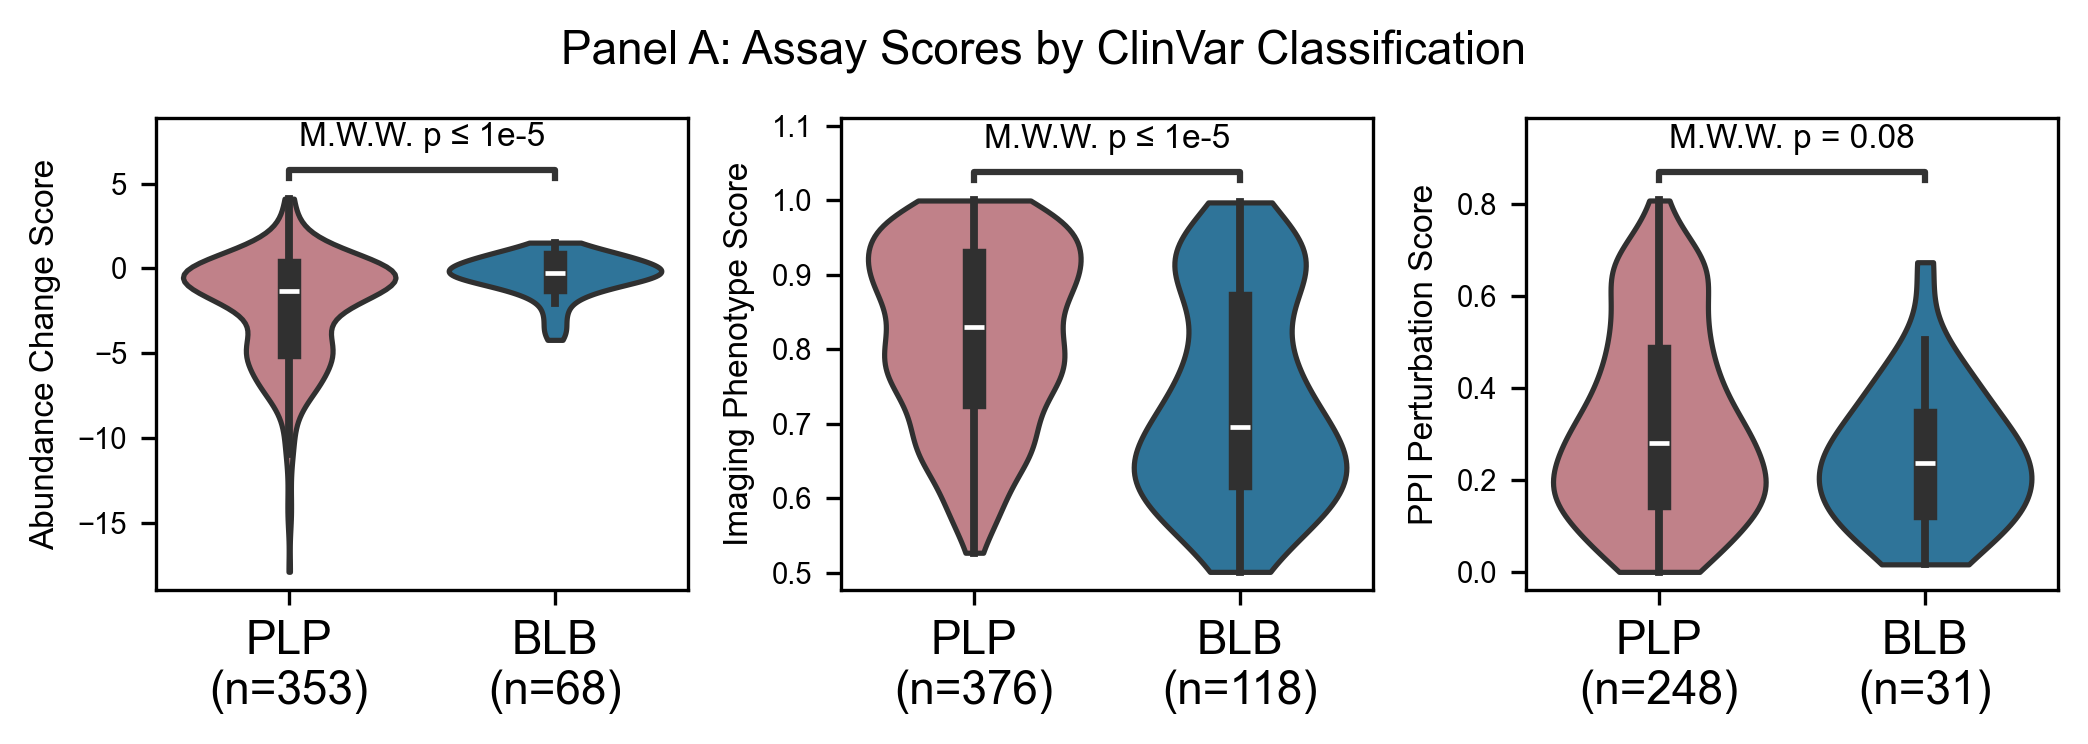


Panel A Statistics (Mann-Whitney U):

Dual-IPA:
  U = 7183
  p = 1.57e-07
  r = 0.402

Imaging:
  U = 30325
  p = 1.77e-09
  r = -0.367

PPI:
  U = 4580
  p = 8.25e-02
  r = -0.191


In [7]:
# Panel A: Score distributions with Mann-Whitney U test
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
panel_a_stats = {}
for idx, (assay_name, score_col) in enumerate(assay_score_cols.items()):
    ax = axes[idx]
    # Use existing plot_assay_scores function
    plot_assay_scores(
        df_plp_blb,
        assay=score_col,
        category='clin_binary',
        ax=ax,
        type='violin',
        order=['PLP', 'BLB'],
        palette=clinvar_palette
    )
    
    # ax.set_title(assay_name)
    ax.set_xlabel('')
    ax.set_ylabel(assay_score_name[score_col])
    
    # Store statistics
    stats = compute_mannwhitney_stats(
        df_plp_blb, score_col, 'clin_binary', 'PLP', 'BLB'
    )
    panel_a_stats[assay_name] = stats

fig.suptitle('Panel A: Assay Scores by ClinVar Classification', y=.96, fontsize=11)
plt.tight_layout()
plt.show()

# # Save figure
# fig.savefig(f'{OUTPUT_DIR}/figure2_panel_a.pdf', bbox_inches='tight', dpi=300)

# Print statistics
print("\nPanel A Statistics (Mann-Whitney U):")
for assay, stats in panel_a_stats.items():
    if stats:
        print(f"\n{assay}:")
        print(f"  U = {stats['U_statistic']:.0f}")
        print(f"  p = {stats['p_value']:.2e}")
        print(f"  r = {stats['effect_size_r']:.3f}")

---
## Panel B: Assay Hit Overlap (UpSet Plot)

Pathogenic variants with at least one hit: 211


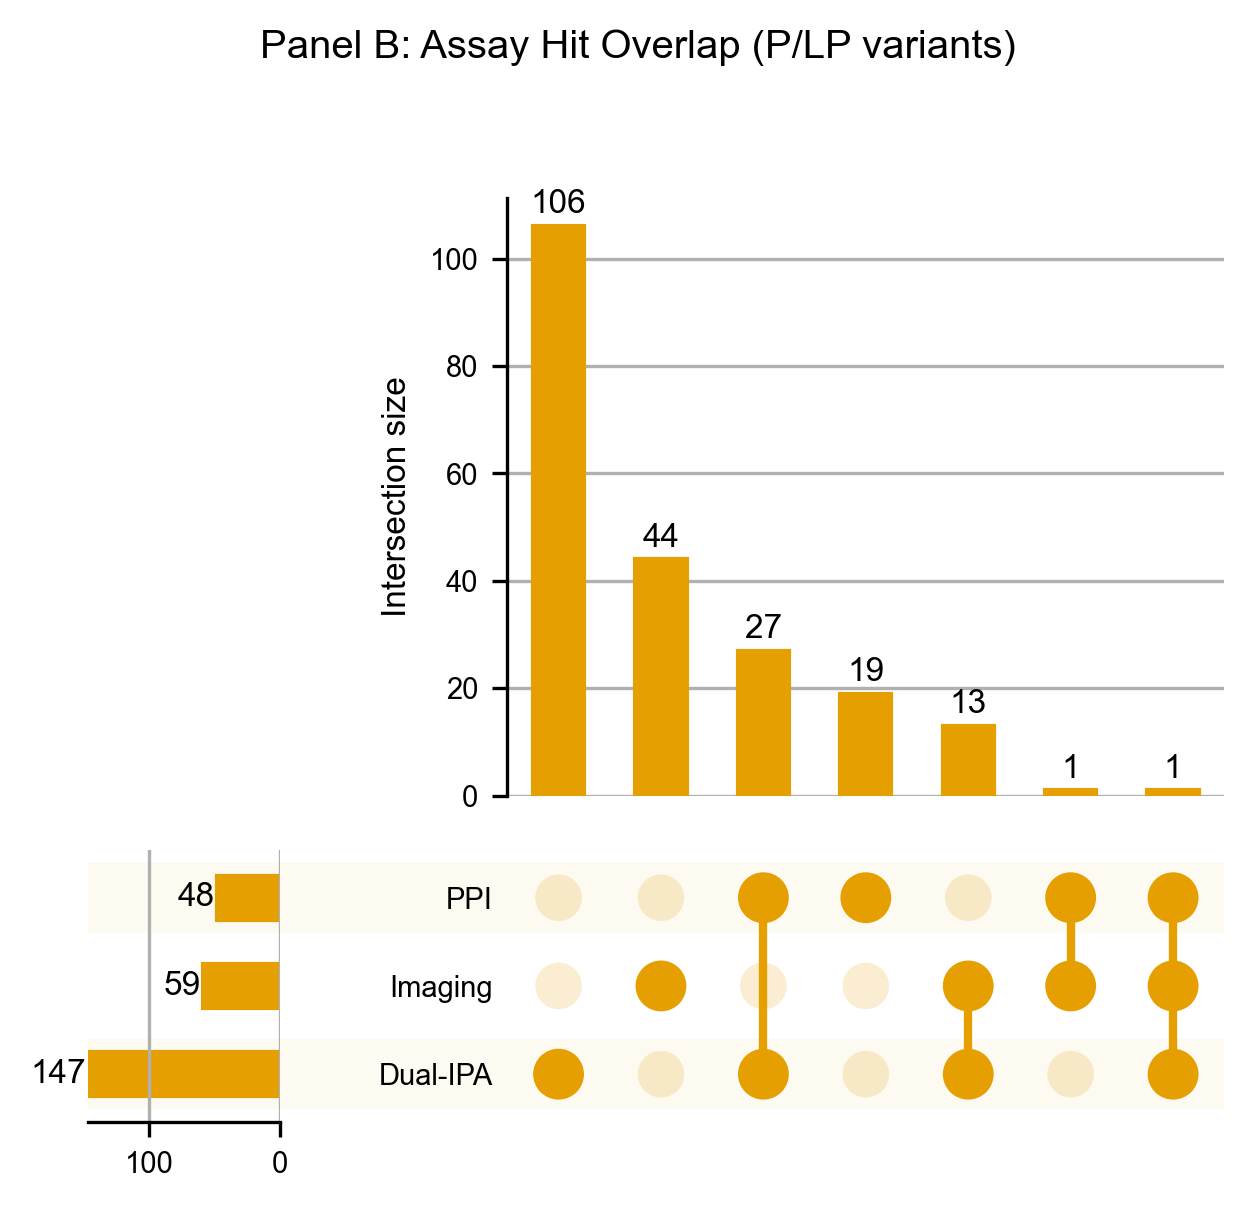

In [8]:
from upsetplot import UpSet, from_memberships

# Panel B: UpSet plot for pathogenic variants
df_patho = df.filter(pl.col('clin_binary') == 'PLP')

# Get hit status for each assay
upset_data = []
for i in range(len(df_patho)):
    row = df_patho.row(i, named=True)
    memberships = []
    
    if row.get('dualipa_hit') == True:
        memberships.append('Dual-IPA')
    if row.get('imaging_hit') == True:
        memberships.append('Imaging')
    if row.get('ppi_hit') == True:
        memberships.append('PPI')
    
    if memberships:  # Only include variants with at least one hit
        upset_data.append(memberships)

print(f"Pathogenic variants with at least one hit: {len(upset_data)}")

# Create UpSet plot
if len(upset_data) > 0:
    upset_series = from_memberships(upset_data)
    
    fig = plt.figure(figsize=(5, 3))
    upset = UpSet(
        upset_series,
        subset_size='count',
        show_counts=True,
        sort_by='cardinality',
        facecolor=assay_palette['Dual-IPA']
    )
    upset.plot(fig=fig)
    plt.suptitle('Panel B: Assay Hit Overlap (P/LP variants)', y=1.02)
    plt.show()
    # # Save
    # fig.savefig(f'{OUTPUT_DIR}/figure2_panel_b.pdf', bbox_inches='tight', dpi=300)
else:
    print("No pathogenic variants with hits found.")

---
## Structural Context Analysis

### Part 1: Global View (All Clinically Classified Variants)

Examining structural bias in assay scores across all P/LP + B/LB variants to establish baseline patterns.

In [9]:
def structural_score_analysis(df, struct_col, struct_groups, subset_name='All'):
    """Compute Mann-Whitney U stats for all assays by structural category."""
    results = []
    for assay_name, score_col in assay_score_cols.items():
        df_sub = df.filter(pl.col(struct_col).is_in(struct_groups) & pl.col(score_col).is_not_null())
        g1 = df_sub.filter(pl.col(struct_col) == struct_groups[0])[score_col].to_numpy()
        g2 = df_sub.filter(pl.col(struct_col) == struct_groups[1])[score_col].to_numpy()
        
        if len(g1) > 0 and len(g2) > 0:
            stat, pval = mannwhitneyu(g1, g2, alternative='two-sided')
            results.append({
                'Subset': subset_name, 'Assay': assay_name,
                'Structural': struct_col.replace('_binary', '').upper(),
                f'{struct_groups[0]}': f'{np.median(g1):.3f} (n={len(g1)})',
                f'{struct_groups[1]}': f'{np.median(g2):.3f} (n={len(g2)})',
                'p_value': pval,
                'Sig': get_significance_stars(pval)
            })
    return pd.DataFrame(results)

### Part 1: Unbiased Overall View (P/LP + B/LB Combined)

First, we examine structural patterns across all variants to establish baseline expectations.

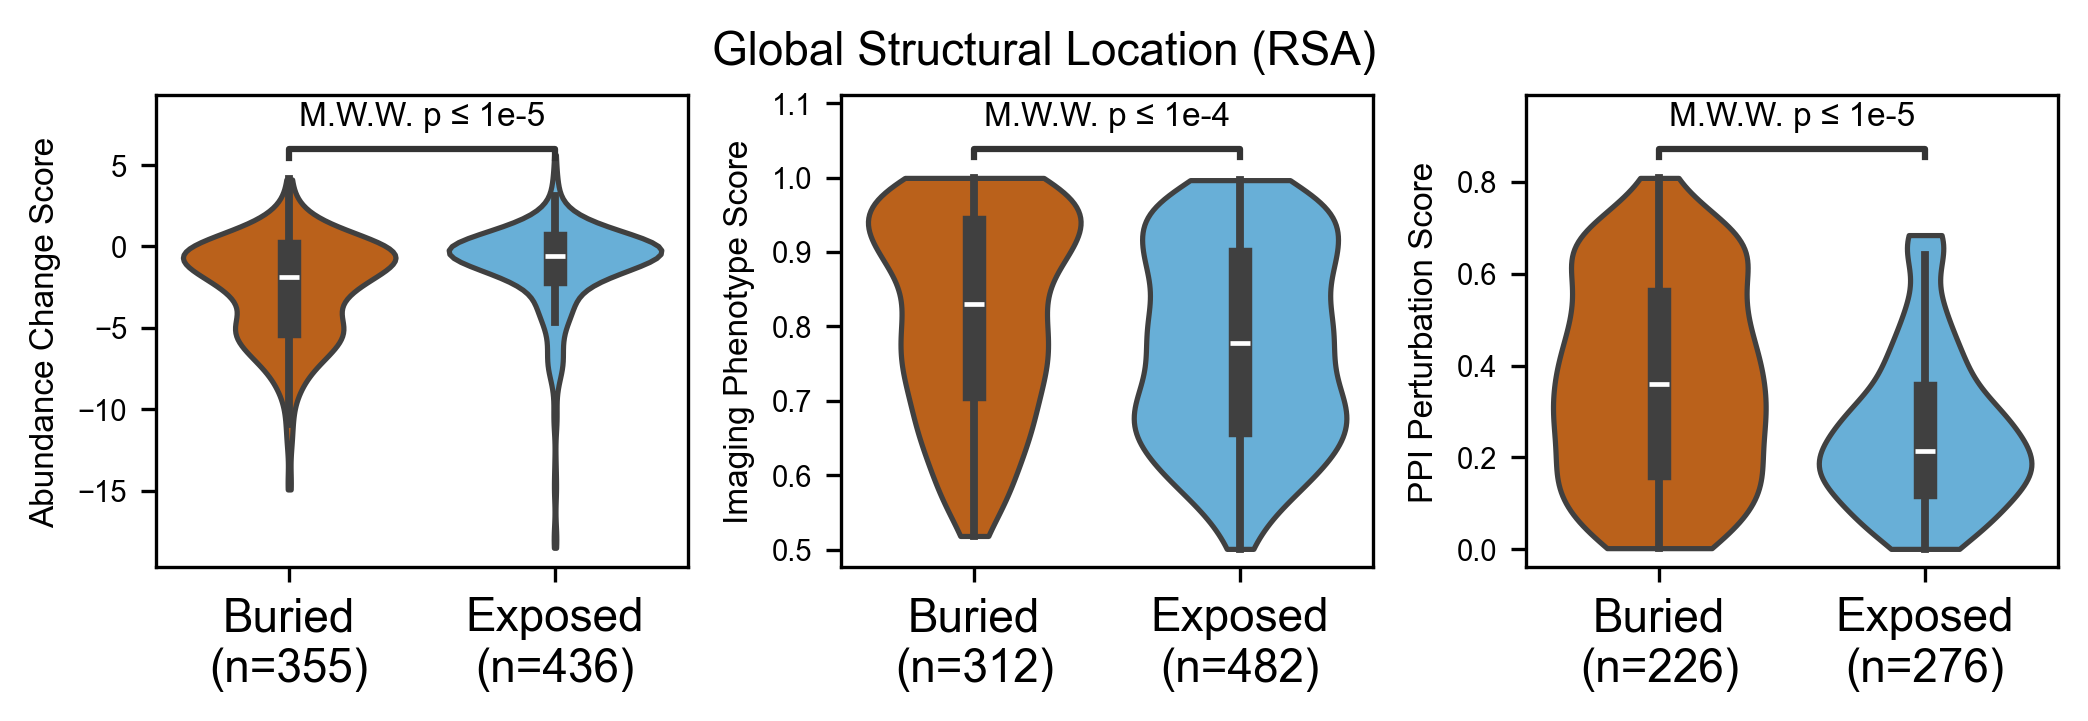

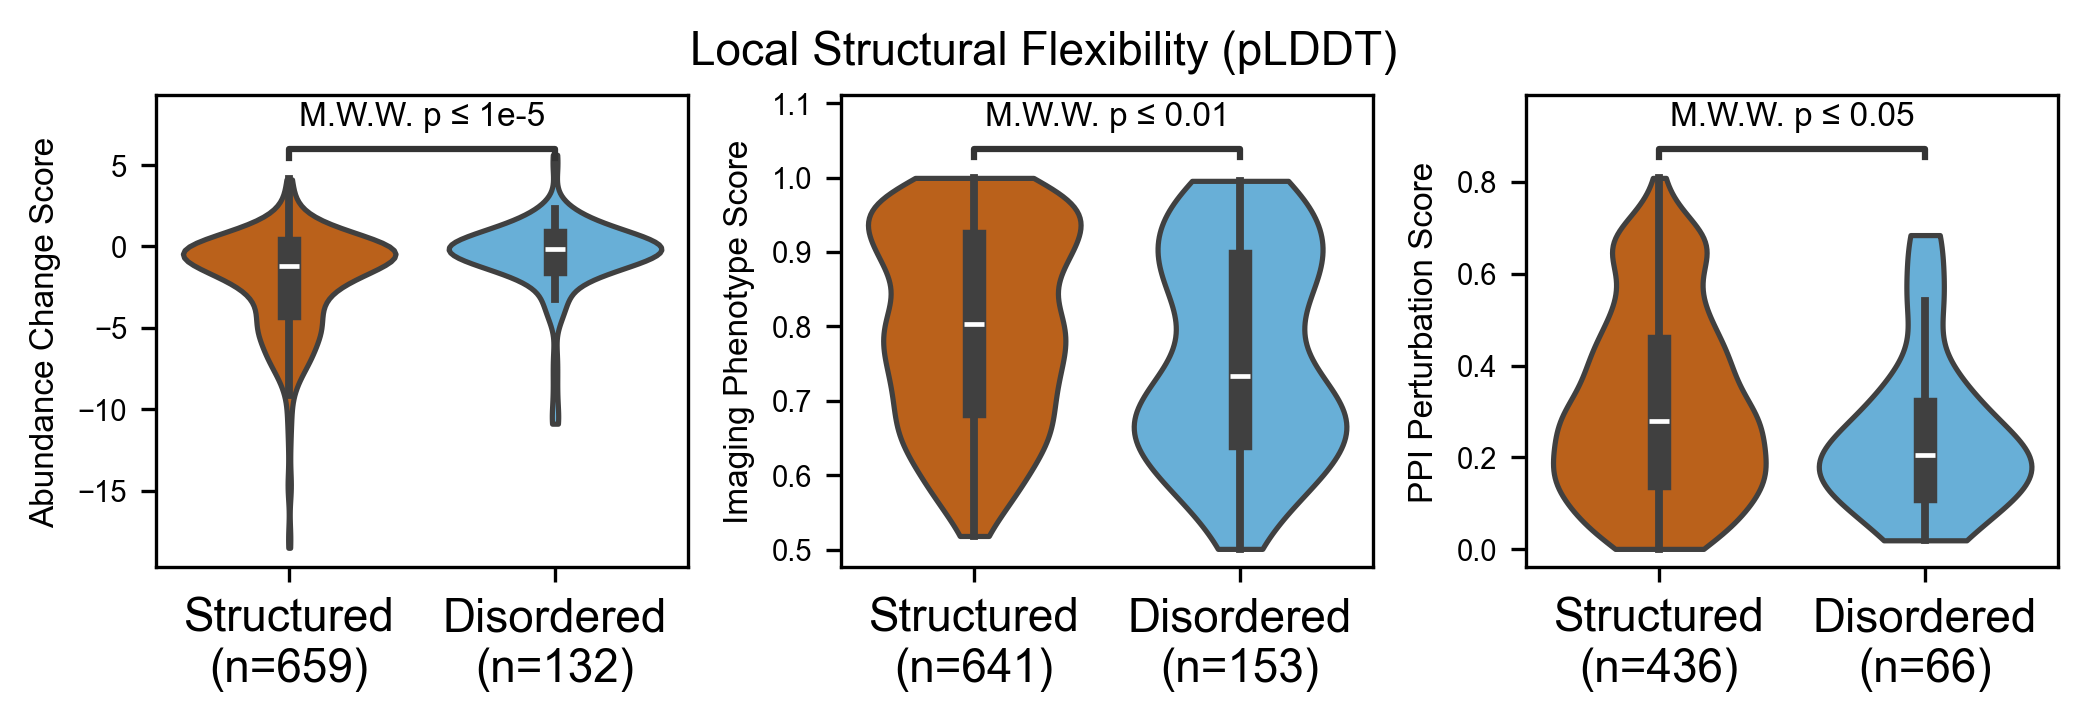

In [10]:
# Overall structural analysis (P/LP + B/LB combined)
# print("=" * 70)
# print("UNBIASED OVERALL VIEW: Structural patterns (All variants)")
# print("=" * 70)

# # RSA analysis
# rsa_overall = structural_score_analysis(df, 'rsa_binary', ['Buried', 'Exposed'])
# print("\n--- RSA (Buried vs Exposed) ---")
# print(rsa_overall.to_string(index=False))

# # pLDDT analysis
# plddt_overall = structural_score_analysis(df, 'plddt_binary', ['Structured', 'Disordered'])
# print("\n--- pLDDT (Structured vs Disordered) ---")
# print(plddt_overall.to_string(index=False))

# print("\n" + "=" * 70)
# print("KEY FINDING: All assays show significantly higher scores in Buried/Structured regions")
# print("This reflects pathogenic variants being enriched at structurally important positions")
# print("=" * 70)

# Visualization: Structural score comparison (P/LP only)
# fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
# RSA comparison (top row)
for idx, (assay_name, score_col) in enumerate(assay_score_cols.items()):
    ax = axes[idx]
    plot_data = df.filter(pl.col(score_col).is_not_null() & pl.col('rsa_binary').is_not_null()).with_columns(
        pl.col("rsa_binary").cast(pl.Enum(['Buried', 'Exposed'])).alias("rsa_binary")
    ).sort("rsa_binary") #.to_pandas()
    # Use existing plot_assay_scores function
    plot_assay_scores(
        plot_data,
        assay=score_col,
        category='rsa_binary',
        ax=ax,
        type='violin',
        order=['Buried', 'Exposed'],
        palette=rsa_palette
    )
    # sns.violinplot(data=plot_data, x='rsa_binary', y=score_col, order=['Buried', 'Exposed'],
    #                palette=[assay_palette[assay_name]]*2, ax=ax, cut=0)
    # # Add stats annotation
    # stats = rsa_overall[rsa_overall['Assay'] == assay_name].iloc[0] if len(rsa_overall[rsa_overall['Assay'] == assay_name]) > 0 else None
    # if stats is not None:
    #     ax.text(0.5, 0.95, f"p={stats['p_value']:.4f}\n{stats['Sig']}", transform=ax.transAxes,
    #             ha='center', va='top', fontsize=8, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    # ax.set_title(f'{assay_name.upper()}\n(RSA)', fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel(assay_score_name[score_col])

fig.suptitle('Global Structural Location (RSA)', y=.93, fontsize=11)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
# pLDDT comparison (bottom row)
for idx, (assay_name, score_col) in enumerate(assay_score_cols.items()):
    ax = axes[idx]
    plot_data = df.filter(pl.col(score_col).is_not_null() & pl.col('plddt_binary').is_not_null()).with_columns(
        pl.col("plddt_binary").cast(pl.Enum(['Structured', 'Disordered'])).alias("plddt_binary")
    ).sort("plddt_binary")#.to_pandas()
    # Use existing plot_assay_scores function
    plot_assay_scores(
        plot_data,
        assay=score_col,
        category='plddt_binary',
        ax=ax,
        type='violin',
        order=['Structured', 'Disordered'],
        palette=plddt_palette
    )
    # sns.violinplot(data=plot_data, x='plddt_binary', y=score_col, order=['Structured', 'Disordered'],
    #                palette=[assay_palette[assay_name]]*2, ax=ax, cut=0)
    # stats = plddt_overall[plddt_overall['Assay'] == assay_name].iloc[0] if len(plddt_overall[plddt_overall['Assay'] == assay_name]) > 0 else None
    # if stats is not None:
    #     ax.text(0.5, 0.95, f"p={stats['p_value']:.4f}\n{stats['Sig']}", transform=ax.transAxes,
    #             ha='center', va='top', fontsize=8, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # ax.set_title(f'{assay_name.upper()}\n(pLDDT)', fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel(assay_score_name[score_col])

fig.suptitle('Local Structural Flexibility (pLDDT)', y=.93, fontsize=11)
plt.tight_layout()
plt.show()

### Part 2: P/LP-Focused Comparison - Assay Differences

When limiting to pathogenic variants only, do structural features still predict assay scores?
This reveals which assays are structure-dependent vs structure-agnostic.

P/LP variants: 668

P/LP ONLY: Structural patterns within pathogenic variants


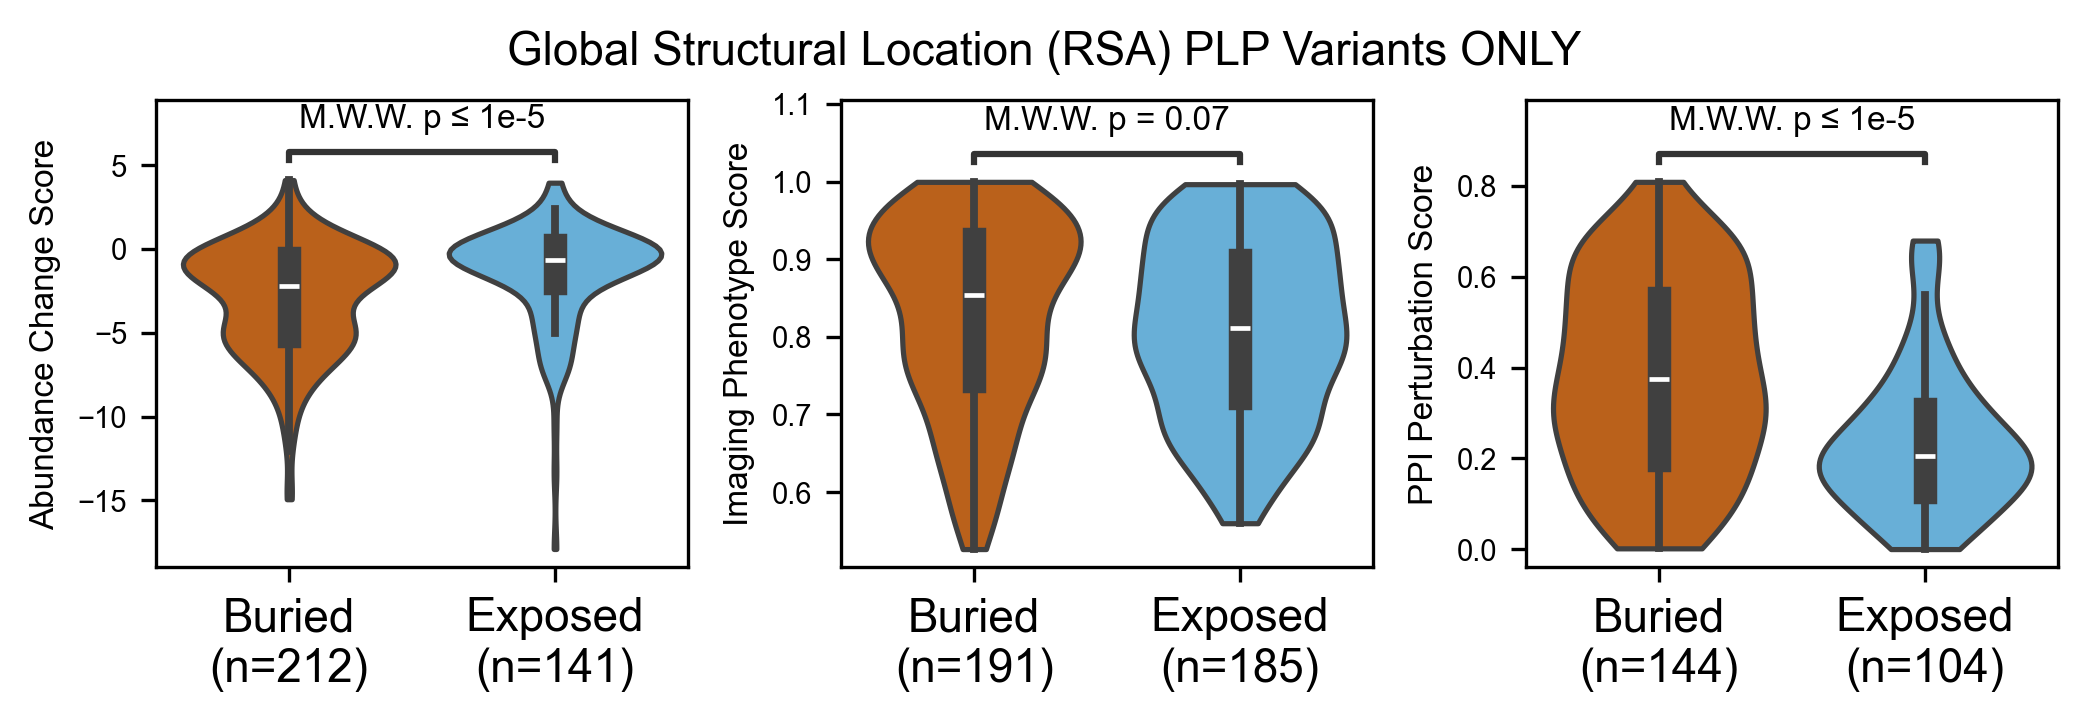

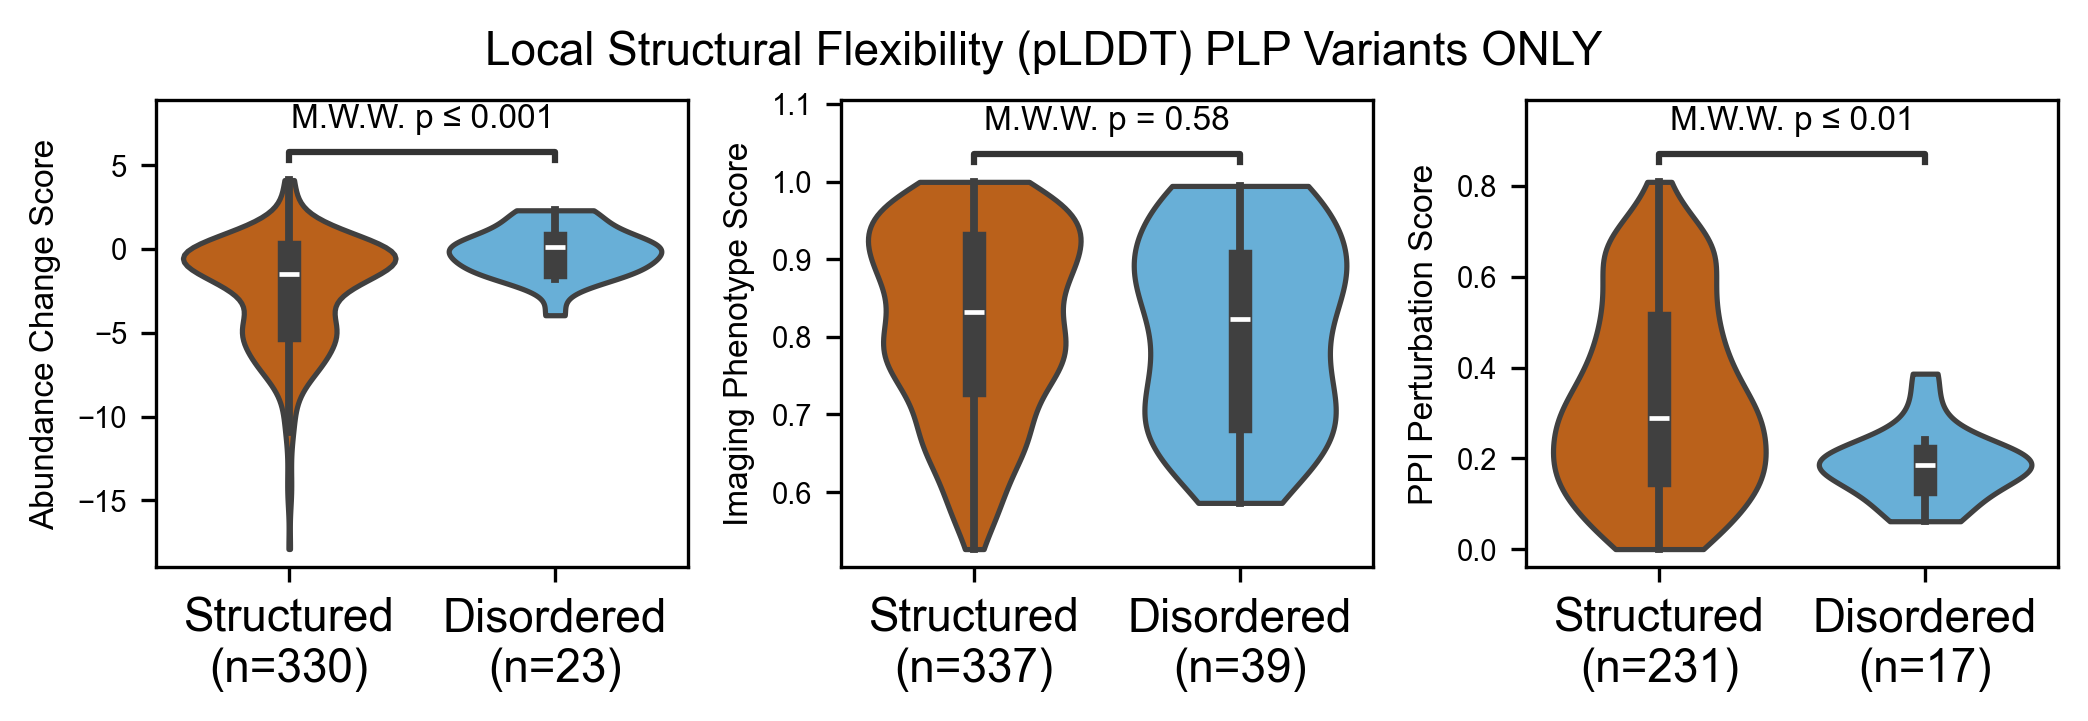


KEY OBSERVATION:
- Dual-IPA and PPI: STILL show significant structural bias within P/LP
- Imaging: NO significant structural bias within P/LP variants
→ Imaging captures complementary mechanisms independent of structural position


In [11]:
# P/LP-only structural analysis
df_plp = df.filter(pl.col('clin_binary') == 'PLP')
print(f"P/LP variants: {len(df_plp)}")

print("\n" + "=" * 70)
print("P/LP ONLY: Structural patterns within pathogenic variants")
print("=" * 70)

# # RSA analysis - P/LP only
# rsa_plp = structural_score_analysis(df_plp, 'rsa_binary', ['Buried', 'Exposed'], 'P/LP only')
# print("\n--- RSA (Buried vs Exposed) ---")
# print(rsa_plp.to_string(index=False))

# # pLDDT analysis - P/LP only
# plddt_plp = structural_score_analysis(df_plp, 'plddt_binary', ['Structured', 'Disordered'], 'P/LP only')
# print("\n--- pLDDT (Structured vs Disordered) ---")
# print(plddt_plp.to_string(index=False))

# # Combine for comparison table
# print("\n" + "=" * 70)
# print("COMPARISON: Overall vs P/LP-only")
# print("=" * 70)
# comparison = pd.concat([rsa_overall, rsa_plp, plddt_overall, plddt_plp])
# comparison_pivot = comparison.pivot_table(index=['Assay', 'Structural'], columns='Subset', 
#                                           values='Sig', aggfunc='first')
# print(comparison_pivot)

# Visualization: Structural score comparison (P/LP only)
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
# RSA comparison (top row)
for idx, (assay_name, score_col) in enumerate(assay_score_cols.items()):
    ax = axes[idx]
    plot_data = df_plp.filter(pl.col(score_col).is_not_null() & pl.col('rsa_binary').is_not_null()).with_columns(
        pl.col("rsa_binary").cast(pl.Enum(['Buried', 'Exposed'])).alias("rsa_binary")
    ).sort("rsa_binary") #.to_pandas().to_pandas()
    # Use existing plot_assay_scores function
    plot_assay_scores(
        plot_data,
        assay=score_col,
        category='rsa_binary',
        ax=ax,
        type='violin',
        order=['Buried', 'Exposed'],
        palette=rsa_palette
    )
    # sns.violinplot(data=plot_data, x='rsa_binary', y=score_col, order=['Buried', 'Exposed'],
    #                palette=[assay_palette[assay_name]]*2, ax=ax, cut=0)
    # # Add stats annotation
    # stats = rsa_overall[rsa_overall['Assay'] == assay_name].iloc[0] if len(rsa_overall[rsa_overall['Assay'] == assay_name]) > 0 else None
    # if stats is not None:
    #     ax.text(0.5, 0.95, f"p={stats['p_value']:.4f}\n{stats['Sig']}", transform=ax.transAxes,
    #             ha='center', va='top', fontsize=8, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    # ax.set_title(f'{assay_name.upper()}\n(RSA)', fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel(assay_score_name[score_col])
fig.suptitle('Global Structural Location (RSA) PLP Variants ONLY', y=.93, fontsize=11)
plt.tight_layout()
display(fig)

# pLDDT comparison (bottom row)
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for idx, (assay_name, score_col) in enumerate(assay_score_cols.items()):
    ax = axes[idx]
    plot_data = df_plp.filter(pl.col(score_col).is_not_null() & pl.col('plddt_binary').is_not_null()).with_columns(
        pl.col("plddt_binary").cast(pl.Enum(['Structured', 'Disordered'])).alias("plddt_binary")
    ).sort("plddt_binary")#.to_pandas()
    # Use existing plot_assay_scores function
    plot_assay_scores(
        plot_data,
        assay=score_col,
        category='plddt_binary',
        ax=ax,
        type='violin',
        order=['Structured', 'Disordered'],
        palette=plddt_palette
    )
    # sns.violinplot(data=plot_data, x='plddt_binary', y=score_col, order=['Structured', 'Disordered'],
    #                palette=[assay_palette[assay_name]]*2, ax=ax, cut=0)

    # stats = plddt_overall[plddt_overall['Assay'] == assay_name].iloc[0] if len(plddt_overall[plddt_overall['Assay'] == assay_name]) > 0 else None
    # if stats is not None:
    #     ax.text(0.5, 0.95, f"p={stats['p_value']:.4f}\n{stats['Sig']}", transform=ax.transAxes,
    #             ha='center', va='top', fontsize=8, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # ax.set_title(f'{assay_name.upper()}\n(pLDDT)', fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel(assay_score_name[score_col])

fig.suptitle('Local Structural Flexibility (pLDDT) PLP Variants ONLY', y=.93, fontsize=11)
plt.tight_layout()
display(fig)

print("\nKEY OBSERVATION:")
print("- Dual-IPA and PPI: STILL show significant structural bias within P/LP")
print("- Imaging: NO significant structural bias within P/LP variants")
print("→ Imaging captures complementary mechanisms independent of structural position")

### Part 3: Functional Feature Analysis

Why does imaging lose structural sensitivity within P/LP?
Analyze PTM sites, signal peptides, and localization-related features enriched in disordered/exposed regions.

#### Comprehensive G2P Annotation Categories for Protein Localization/Trafficking

**Category 1: Targeting/Sorting Signals**
- **Signal peptide** (`g2p_Signal (UniProt)`): N-terminal sequences directing proteins to ER for secretion or membrane insertion
  - *Reference*: von Heijne, 1990. Annu Rev Biophys Chem 19:167-88
- **Transit peptide** (`g2p_Transit peptide (UniProt)`): Sequences targeting proteins to mitochondria or chloroplasts
  - *Reference*: Emanuelsson et al., 2000. J Mol Biol 300:1005-16
- **Motif (NLS/export)** (`g2p_Motif (UniProt)`): Nuclear localization signals (NLS) and nuclear export signals (NES)
  - *Reference*: Lange et al., 2007. J Biol Chem 282:5101-5

**Category 2: Membrane Topology**
- **Transmembrane** (`g2p_Transmembrane (UniProt)`): Regions spanning the membrane
  - *Reference*: Krogh et al., 2001. J Mol Biol 305:567-80
- **Topological domain** (`g2p_Topological domain (UniProt)`): Cytoplasmic, extracellular, or lumenal orientation
  - *Reference*: UniProt Consortium, 2019. Nucleic Acids Res 47:D506-15
- **Intramembrane** (`g2p_Intramembrane (UniProt)`): Regions within membranes but not spanning
  - *Reference*: Viklund et al., 2008. Bioinformatics 24:2928-9

**Category 3: Post-translational Modifications (PTMs) Affecting Localization**
- **Phosphorylation** (`g2p_Phosphorylation`): Regulates localization via conformational changes or binding partner recognition
  - *Reference*: Nishi et al., 2014. Mol Cell 55:153-66
- **Ubiquitination** (`g2p_Ubiquitination`): Targets proteins for degradation or regulates trafficking
  - *Reference*: Komander & Rape, 2012. Annu Rev Biochem 81:203-29
- **Acetylation** (`g2p_Acetylation`): Affects nuclear/cytoplasmic shuttling
  - *Reference*: Choudhary et al., 2009. Science 325:834-40
- **Methylation** (`g2p_Methylation`): Can influence nuclear localization
  - *Reference*: Bedford & Clarke, 2009. Mol Cell 33:1-13
- **Glycosylation** (`g2p_Glycosylation (UniProt)`): N-linked and O-linked modifications affecting ER/Golgi trafficking
  - *Reference*: Varki, 2017. Glycobiology 27:3-49
- **Modified residue** (`g2p_Modified residue (UniProt)`): General PTM annotations
  - *Reference*: Khoury et al., 2011. Sci Rep 1:90

**Category 4: Structural Features Affecting Trafficking**
- **Propeptide** (`g2p_Propeptide (UniProt)`): Cleaved sequences required for proper folding/targeting
  - *Reference*: Seidah & Chretien, 1999. Brain Res 848:45-62
- **Coiled coil** (`g2p_Coiled coil (UniProt)`): Protein-protein interaction domains, often involved in membrane tethering
  - *Reference*: Lupas & Bassler, 2017. Trends Biochem Sci 42:130-40

**Composite Feature: Localization/Trafficking-Related Residues**
Combines all above categories to identify residues with any annotation relevant to protein localization, trafficking, or membrane topology.

In [12]:
# Define comprehensive functional feature columns from G2P annotations
# Organized by category for clarity

# Category 1: Targeting/Sorting Signals
targeting_signals = {
    'Signal peptide': 'g2p_Signal (UniProt)',
    'Transit peptide': 'g2p_Transit peptide (UniProt)',
    'Motif (NLS/export)': 'g2p_Motif (UniProt)',
}

# Category 2: Membrane Topology
membrane_topology = {
    'Transmembrane': 'g2p_Transmembrane (UniProt)',
    'Topological domain': 'g2p_Topological domain (UniProt)',
    'Intramembrane': 'g2p_Intramembrane (UniProt)',
}

# Category 3: PTMs Affecting Localization
ptm_features = {
    'Phosphorylation': 'g2p_Phosphorylation',
    'Ubiquitination': 'g2p_Ubiquitination',
    'Acetylation': 'g2p_Acetylation',
    'Methylation': 'g2p_Methylation',
    'Glycosylation': 'g2p_Glycosylation (UniProt)',
    'Modified residue': 'g2p_Modified residue (UniProt)',
}

# Category 4: Structural Features Affecting Trafficking
structural_trafficking = {
    'Propeptide': 'g2p_Propeptide (UniProt)',
    'Coiled coil': 'g2p_Coiled coil (UniProt)',
}

# Combine all into comprehensive functional_features dict
functional_features = {**targeting_signals, **membrane_topology, **ptm_features, **structural_trafficking}

print(f"Total functional feature categories: {len(functional_features)}")
print("\nFeatures by category:")
print(f"  Targeting/Sorting Signals: {list(targeting_signals.keys())}")
print(f"  Membrane Topology: {list(membrane_topology.keys())}")
print(f"  PTMs: {list(ptm_features.keys())}")
print(f"  Structural/Trafficking: {list(structural_trafficking.keys())}")

# Create binary indicators using polars
feature_cols = []
for name, col in functional_features.items():
    safe_name = name.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_')
    if col in df.columns:
        df = df.with_columns([
            (pl.col(col).is_not_null() & (pl.col(col) != '.')).alias(f'has_{safe_name}')
        ])
        feature_cols.append(f'has_{safe_name}')
    else:
        print(f"  Warning: Column '{col}' not found in data")

# Create combined feature indicators with fill_null handling
targeting_cols = [f'has_{n.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")}' 
                  for n in targeting_signals.keys() if f'has_{n.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")}' in df.columns]
membrane_cols = [f'has_{n.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")}' 
                 for n in membrane_topology.keys() if f'has_{n.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")}' in df.columns]
ptm_cols = [f'has_{n.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")}' 
            for n in ptm_features.keys() if f'has_{n.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")}' in df.columns]
struct_cols = [f'has_{n.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")}' 
               for n in structural_trafficking.keys() if f'has_{n.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")}' in df.columns]

# Combined indicators
df = df.with_columns([
    # Any targeting/sorting signal
    pl.any_horizontal([pl.col(c).fill_null(False) for c in targeting_cols]).alias('has_targeting_signal'),
    # Any membrane topology feature
    pl.any_horizontal([pl.col(c).fill_null(False) for c in membrane_cols]).alias('has_membrane_topology'),
    # Any PTM site (expanded)
    pl.any_horizontal([pl.col(c).fill_null(False) for c in ptm_cols]).alias('has_any_ptm'),
    # Any structural/trafficking feature
    pl.any_horizontal([pl.col(c).fill_null(False) for c in struct_cols]).alias('has_structural_trafficking'),
])

# Create the COMPOSITE column: any localization/trafficking-related annotation
all_feature_cols = targeting_cols + membrane_cols + ptm_cols + struct_cols
df = df.with_columns([
    pl.any_horizontal([pl.col(c).fill_null(False) for c in all_feature_cols]).alias('has_loc_trafficking_feature')
])

# Legacy compatibility columns (keep for backward compatibility with existing code)
df = df.with_columns([
    pl.col('has_targeting_signal').alias('has_loc_feature'),
    pl.any_horizontal([pl.col('has_Phosphorylation').fill_null(False), 
                       pl.col('has_Ubiquitination').fill_null(False)]).alias('has_ptm')
])

print("\nFeature indicator columns created.")
print(f"Composite column 'has_loc_trafficking_feature' created combining {len(all_feature_cols)} features.")

Total functional feature categories: 14

Features by category:
  Targeting/Sorting Signals: ['Signal peptide', 'Transit peptide', 'Motif (NLS/export)']
  Membrane Topology: ['Transmembrane', 'Topological domain', 'Intramembrane']
  PTMs: ['Phosphorylation', 'Ubiquitination', 'Acetylation', 'Methylation', 'Glycosylation', 'Modified residue']
  Structural/Trafficking: ['Propeptide', 'Coiled coil']

Feature indicator columns created.
Composite column 'has_loc_trafficking_feature' created combining 14 features.


In [13]:
# Analyze feature enrichment in disordered/exposed regions (P/LP only)
df_plp_img = df.filter(
    pl.col('clin_binary') == 'PLP',
    pl.col("imaging_score").is_not_null()
)

print("=" * 70)
print("FUNCTIONAL FEATURE ENRICHMENT ANALYSIS (Imaging scored P/LP variants)")
print("=" * 70)

def feature_enrichment_test(df, feature_col, struct_col, struct_groups):
    """Fisher's exact test for feature enrichment in structural categories."""
    g1 = df.filter(pl.col(struct_col) == struct_groups[0])
    g2 = df.filter(pl.col(struct_col) == struct_groups[1])
    
    g1_has = g1.filter(pl.col(feature_col)).height
    g1_total = g1.height
    g2_has = g2.filter(pl.col(feature_col)).height
    g2_total = g2.height
    
    if g1_total > 0 and g2_total > 0:
        table = [[g1_has, g1_total - g1_has], [g2_has, g2_total - g2_has]]
        odds_ratio, pval = fisher_exact(table)
        return {
            f'{struct_groups[0]}': f'{g1_has}/{g1_total} ({g1_has/g1_total*100:.1f}%)',
            f'{struct_groups[1]}': f'{g2_has}/{g2_total} ({g2_has/g2_total*100:.1f}%)',
            'OR': odds_ratio, 'p': pval,
            'Sig': '*' if pval < 0.05 else 'ns'
        }
    return None

# Feature enrichment by pLDDT
print("\n--- Feature Enrichment in Disordered vs Structured (pLDDT) ---")
plddt_enrichment = []
for name, col in functional_features.items():
    safe_name = name.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_')
    feat_col = f'has_{safe_name}'
    if feat_col in df_plp_img.columns:
        result = feature_enrichment_test(df_plp_img, feat_col, 'plddt_binary', ['Disordered', 'Structured'])
        if result:
            result['Feature'] = name
            plddt_enrichment.append(result)

plddt_enrich_df = pd.DataFrame(plddt_enrichment)
if len(plddt_enrich_df) > 0:
    print(plddt_enrich_df[['Feature', 'Disordered', 'Structured', 'OR', 'p', 'Sig']].to_string(index=False))

# Feature enrichment by RSA
print("\n--- Feature Enrichment in Exposed vs Buried (RSA) ---")
rsa_enrichment = []
for name, col in functional_features.items():
    safe_name = name.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_')
    feat_col = f'has_{safe_name}'
    if feat_col in df_plp.columns:
        result = feature_enrichment_test(df_plp, feat_col, 'rsa_binary', ['Exposed', 'Buried'])
        if result:
            result['Feature'] = name
            rsa_enrichment.append(result)

rsa_enrich_df = pd.DataFrame(rsa_enrichment)
if len(rsa_enrich_df) > 0:
    print(rsa_enrich_df[['Feature', 'Exposed', 'Buried', 'OR', 'p', 'Sig']].to_string(index=False))

FUNCTIONAL FEATURE ENRICHMENT ANALYSIS (Imaging scored P/LP variants)

--- Feature Enrichment in Disordered vs Structured (pLDDT) ---
           Feature  Disordered    Structured       OR        p Sig
    Signal peptide 1/39 (2.6%)  0/337 (0.0%)      inf 0.103723  ns
   Transit peptide 0/39 (0.0%)  0/337 (0.0%)      NaN 1.000000  ns
Motif (NLS/export) 1/39 (2.6%)  3/337 (0.9%) 2.929825 0.355889  ns
     Transmembrane 1/39 (2.6%) 11/337 (3.3%) 0.779904 1.000000  ns
Topological domain 0/39 (0.0%)  6/337 (1.8%) 0.000000 1.000000  ns
     Intramembrane 0/39 (0.0%)  0/337 (0.0%)      NaN 1.000000  ns
   Phosphorylation 3/39 (7.7%)  5/337 (1.5%) 5.533333 0.040094   *
    Ubiquitination 0/39 (0.0%)  2/337 (0.6%) 0.000000 1.000000  ns
       Acetylation 1/39 (2.6%)  2/337 (0.6%) 4.407895 0.280678  ns
       Methylation 0/39 (0.0%)  3/337 (0.9%) 0.000000 1.000000  ns
     Glycosylation 0/39 (0.0%)  0/337 (0.0%)      NaN 1.000000  ns
  Modified residue 2/39 (5.1%)  4/337 (1.2%) 4.500000 0.120361

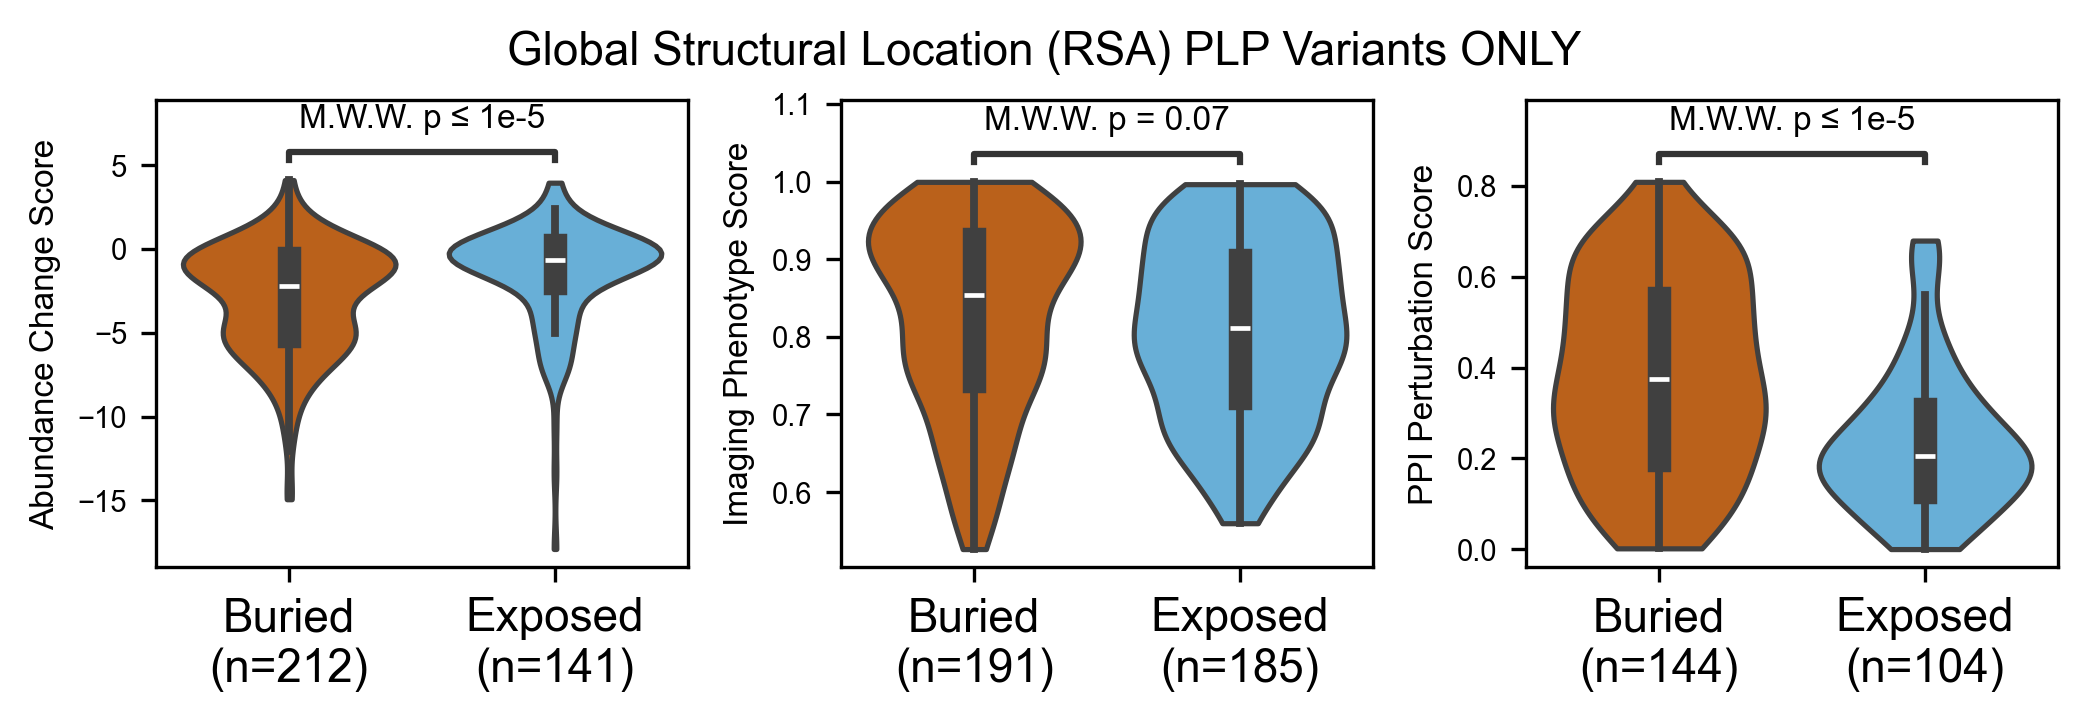

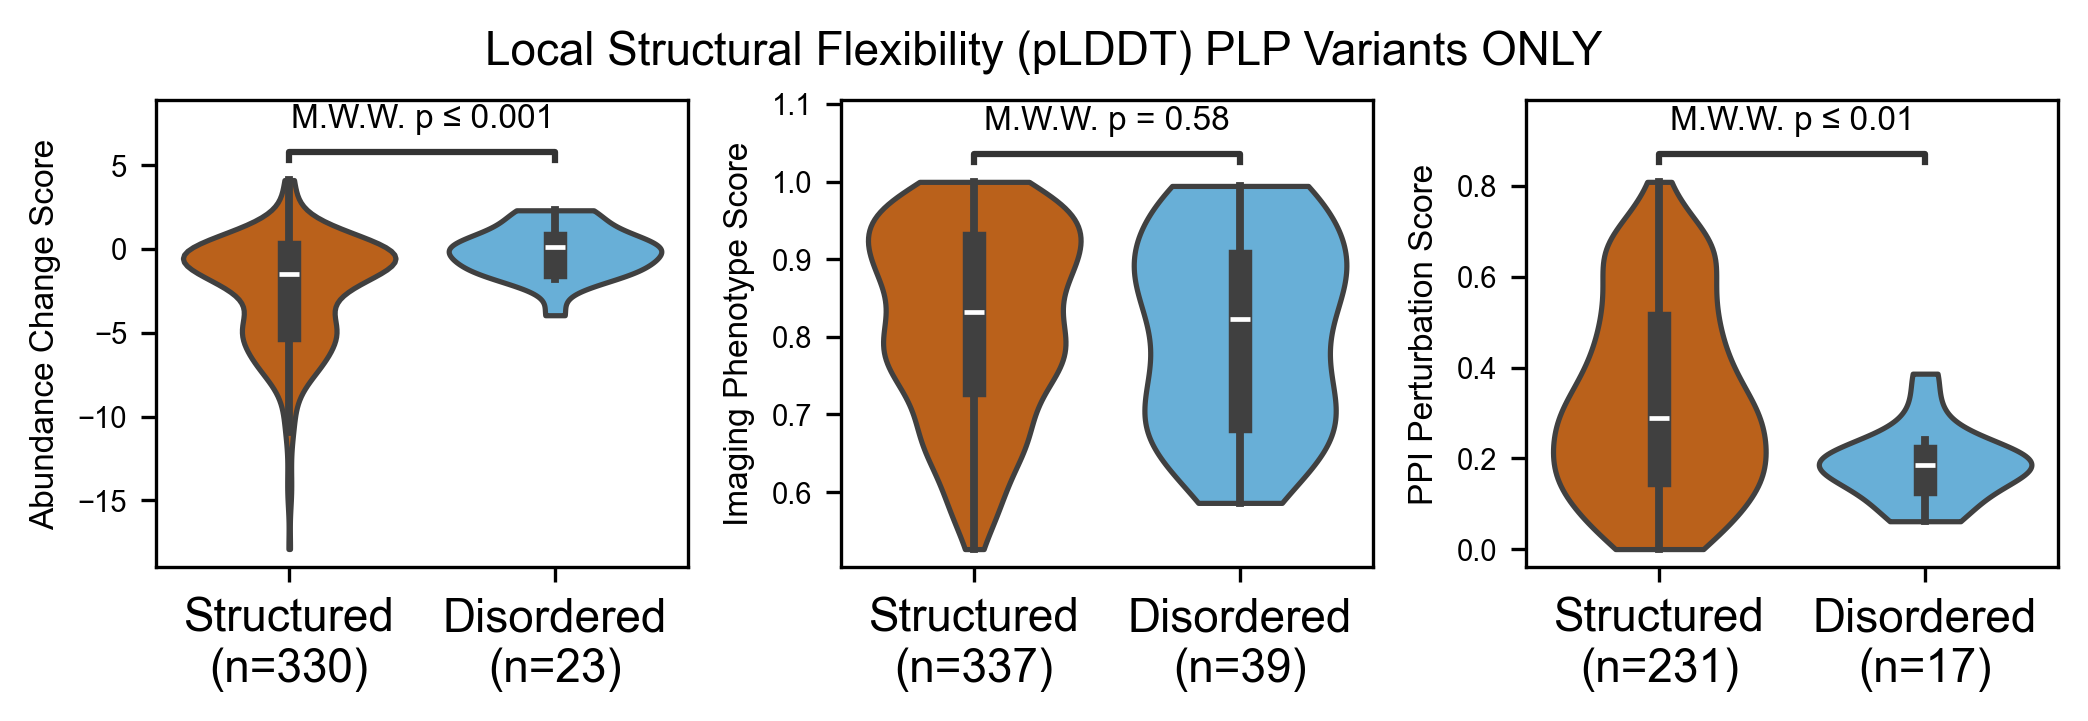

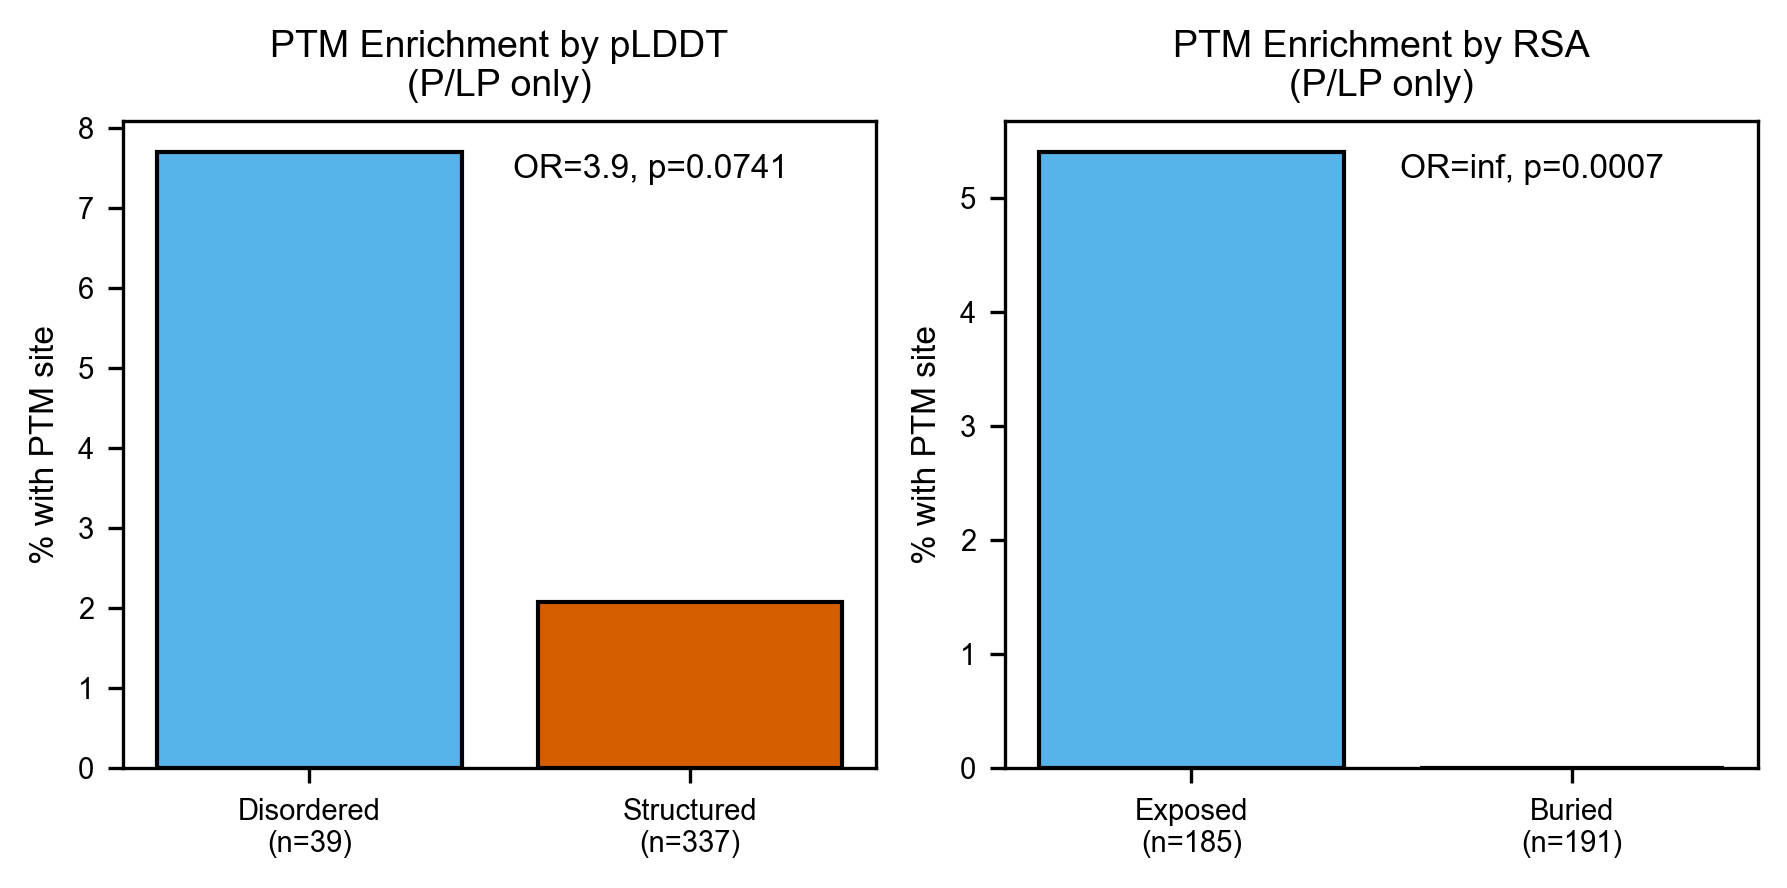

In [14]:
# Summary visualization: PTM enrichment in disordered/exposed
fig, axes = plt.subplots(1, 2, figsize=(6, 3))

# pLDDT enrichment
ax1 = axes[0]
df_plp_plddt = df_plp_img.filter(pl.col('plddt_binary').is_not_null()).to_pandas()
ptm_by_plddt = df_plp_plddt.groupby('plddt_binary')['has_ptm'].agg(['sum', 'count'])
ptm_by_plddt['rate'] = ptm_by_plddt['sum'] / ptm_by_plddt['count'] * 100

bars1 = ax1.bar(['Disordered', 'Structured'], 
        [ptm_by_plddt.loc['Disordered', 'rate'], ptm_by_plddt.loc['Structured', 'rate']],
        color=[plddt_palette['Disordered'], plddt_palette['Structured']], edgecolor='black')
ax1.set_ylabel('% with PTM site')
ax1.set_title('PTM Enrichment by pLDDT\n(P/LP only)')

# Add N labels to x-axis
dis_n = int(ptm_by_plddt.loc['Disordered', 'count'])
struc_n = int(ptm_by_plddt.loc['Structured', 'count'])
ax1.set_xticks([0, 1])
ax1.set_xticklabels([f'Disordered\n(n={dis_n})', f'Structured\n(n={struc_n})'])

# Add stats
ptm_result = feature_enrichment_test(df_plp_img, 'has_ptm', 'plddt_binary', ['Disordered', 'Structured'])
if ptm_result:
    ax1.text(0.7, 0.95, f"OR={ptm_result['OR']:.1f}, p={ptm_result['p']:.4f}",
             transform=ax1.transAxes, ha='center', va='top', fontsize=8)

# RSA enrichment
ax2 = axes[1]
df_plp_rsa = df_plp_img.filter(pl.col('rsa_binary').is_not_null()).to_pandas()
ptm_by_rsa = df_plp_rsa.groupby('rsa_binary')['has_ptm'].agg(['sum', 'count'])
ptm_by_rsa['rate'] = ptm_by_rsa['sum'] / ptm_by_rsa['count'] * 100

bars2 = ax2.bar(['Exposed', 'Buried'],
        [ptm_by_rsa.loc['Exposed', 'rate'], ptm_by_rsa.loc['Buried', 'rate']],
        color=[rsa_palette['Exposed'], rsa_palette['Buried']], edgecolor='black')
ax2.set_ylabel('% with PTM site')
ax2.set_title('PTM Enrichment by RSA\n(P/LP only)')

# Add N labels to x-axis
exp_n = int(ptm_by_rsa.loc['Exposed', 'count'])
bur_n = int(ptm_by_rsa.loc['Buried', 'count'])
ax2.set_xticks([0, 1])
ax2.set_xticklabels([f'Exposed\n(n={exp_n})', f'Buried\n(n={bur_n})'])

# Add stats
ptm_result_rsa = feature_enrichment_test(df_plp_img, 'has_ptm', 'rsa_binary', ['Exposed', 'Buried'])
if ptm_result_rsa:
    ax2.text(0.7, 0.95, f"OR={ptm_result_rsa['OR']:.1f}, p={ptm_result_rsa['p']:.4f}",
             transform=ax2.transAxes, ha='center', va='top', fontsize=8)

plt.tight_layout()
plt.show()

In [15]:
# Comprehensive analysis of composite localization/trafficking feature
# Analyze the composite 'has_loc_trafficking_feature' column
print("=" * 80)
print("COMPOSITE LOCALIZATION/TRAFFICKING FEATURE ANALYSIS (P/LP only)")
print("=" * 80)

# Count variants with any localization/trafficking-related annotation
n_with_feature = df_plp_img.filter(pl.col('has_loc_trafficking_feature')).height
n_total = df_plp_img.height
print(f"\nP/LP variants with localization/trafficking features: {n_with_feature}/{n_total} ({n_with_feature/n_total*100:.1f}%)")

# Breakdown by category
print("\n--- Feature Category Breakdown (P/LP only) ---")
category_counts = {
    'Targeting signals': df_plp_img.filter(pl.col('has_targeting_signal')).height,
    'Membrane topology': df_plp_img.filter(pl.col('has_membrane_topology')).height,
    'Any PTM': df_plp_img.filter(pl.col('has_any_ptm')).height,
    'Structural/Trafficking': df_plp_img.filter(pl.col('has_structural_trafficking')).height,
}
for cat, count in category_counts.items():
    print(f"  {cat}: {count}/{n_total} ({count/n_total*100:.1f}%)")

# Enrichment analysis by structural context
print("\n--- Composite Feature Enrichment in Disordered vs Structured (pLDDT) ---")
loc_result_plddt = feature_enrichment_test(df_plp_img, 'has_loc_trafficking_feature', 'plddt_binary', ['Disordered', 'Structured'])
if loc_result_plddt:
    print(f"  Disordered: {loc_result_plddt['Disordered']}")
    print(f"  Structured: {loc_result_plddt['Structured']}")
    print(f"  OR = {loc_result_plddt['OR']:.2f}, p = {loc_result_plddt['p']:.4f}, {loc_result_plddt['Sig']}")

print("\n--- Composite Feature Enrichment in Exposed vs Buried (RSA) ---")
loc_result_rsa = feature_enrichment_test(df_plp_img, 'has_loc_trafficking_feature', 'rsa_binary', ['Exposed', 'Buried'])
if loc_result_rsa:
    print(f"  Exposed: {loc_result_rsa['Exposed']}")
    print(f"  Buried: {loc_result_rsa['Buried']}")
    print(f"  OR = {loc_result_rsa['OR']:.2f}, p = {loc_result_rsa['p']:.4f}, {loc_result_rsa['Sig']}")

COMPOSITE LOCALIZATION/TRAFFICKING FEATURE ANALYSIS (P/LP only)

P/LP variants with localization/trafficking features: 58/376 (15.4%)

--- Feature Category Breakdown (P/LP only) ---
  Targeting signals: 5/376 (1.3%)
  Membrane topology: 18/376 (4.8%)
  Any PTM: 18/376 (4.8%)
  Structural/Trafficking: 20/376 (5.3%)

--- Composite Feature Enrichment in Disordered vs Structured (pLDDT) ---
  Disordered: 11/39 (28.2%)
  Structured: 47/337 (13.9%)
  OR = 2.42, p = 0.0320, *

--- Composite Feature Enrichment in Exposed vs Buried (RSA) ---


  Exposed: 46/185 (24.9%)
  Buried: 12/191 (6.3%)
  OR = 4.94, p = 0.0000, *


In [18]:
df_plp_plddt

,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,...,has_Modified_residue,has_Propeptide,has_Coiled_coil,has_targeting_signal,has_membrane_topology,has_any_ptm,has_structural_trafficking,has_loc_trafficking_feature,has_loc_feature,has_ptm
0,ABCD1,Arg389Gly,ABCD1_Arg389Gly,NC_000023.11:153736194:C:G,1165C>G,23,153736195,C,G,X,...,False,False,False,False,False,False,False,False,False,False
1,ABCD1,Arg518Gln,ABCD1_Arg518Gln,NC_000023.11:153740155:G:A,1553G>A,23,153740156,G,A,X,...,False,False,False,False,False,False,False,False,False,False
2,AGXT,Ala85Asp,AGXT_Ala85Asp,NC_000002.12:240869257:C:A,254C>A,2,240869258,C,A,2,...,False,False,False,False,False,False,False,False,False,False
3,AGXT,Arg111Gln,AGXT_Arg111Gln,NC_000002.12:240869335:G:A,332G>A,2,240869336,G,A,2,...,False,False,False,False,False,False,False,False,False,False
4,AGXT,Gly116Arg,AGXT_Gly116Arg,NC_000002.12:240869349:G:A,346G>A,2,240869350,G,A,2,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
371,ZC4H2,Arg213Trp,ZC4H2_Arg213Trp,NC_000023.11:64917820:G:A,637C>T,23,64917821,G,A,X,...,False,False,False,False,False,False,False,False,False,False
372,ZC4H2,Leu66His,ZC4H2_Leu66His,NC_000023.11:64921844:A:T,197T>A,23,64921845,A,T,X,...,False,False,True,False,False,False,True,True,False,False
373,ZC4H2,Lys217Arg,ZC4H2_Lys217Arg,NC_000023.11:64917807:T:C,650A>G,23,64917808,T,C,X,...,False,False,False,False,False,False,False,False,False,False
374,ZC4H2,Pro201Ser,ZC4H2_Pro201Ser,NC_000023.11:64917856:G:A,601C>T,23,64917857,G,A,X,...,False,False,False,False,False,False,False,False,False,False


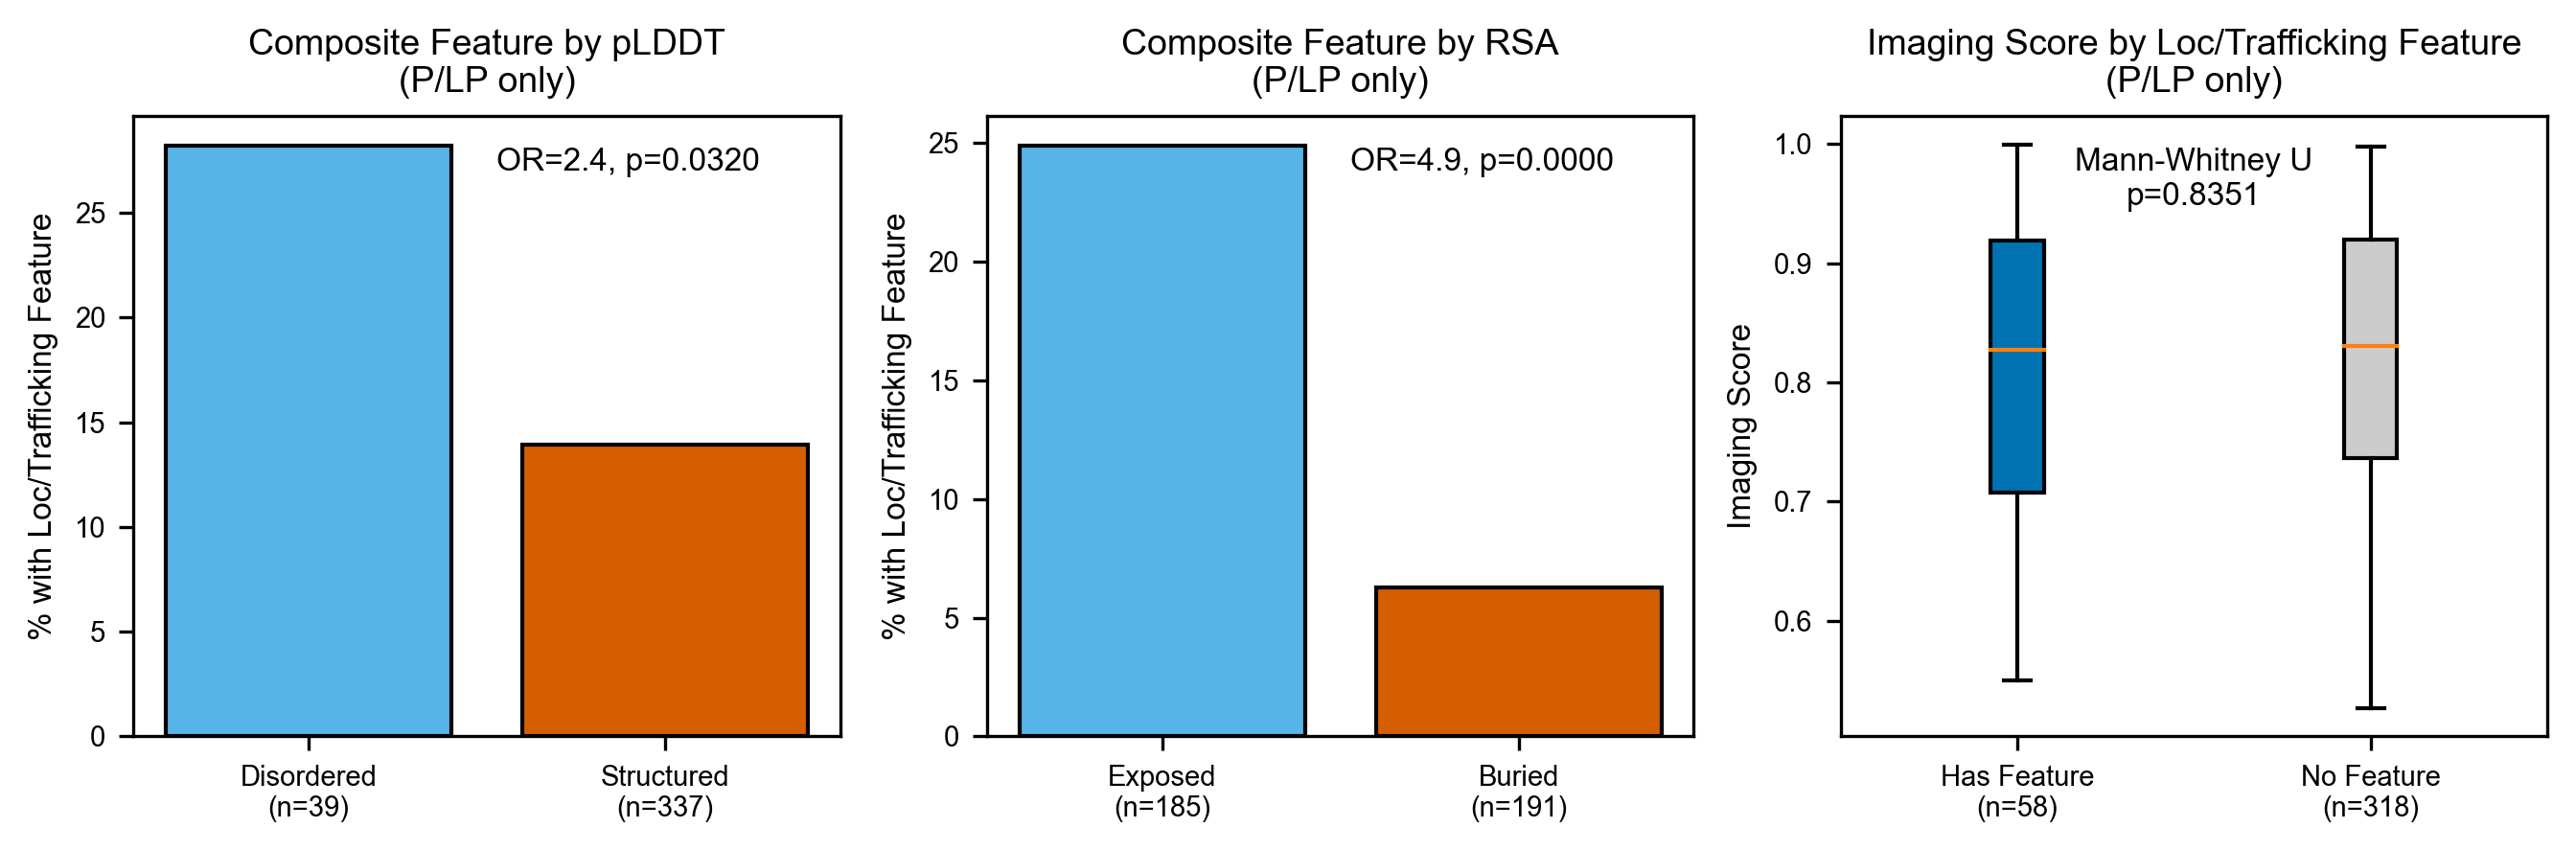


Imaging score comparison:
  Has Loc/Trafficking Feature: median=0.828, n=58
  No Feature: median=0.831, n=318


In [32]:
# Visualization: Composite localization/trafficking feature by structural context
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

# Plot 1: Feature rate by pLDDT
ax1 = axes[0]
df_plp_plddt = df_plp_img.filter(pl.col('plddt_binary').is_not_null()).to_pandas()
loc_by_plddt = df_plp_plddt.groupby('plddt_binary')['has_loc_trafficking_feature'].agg(['sum', 'count'])
loc_by_plddt['rate'] = loc_by_plddt['sum'] / loc_by_plddt['count'] * 100

ax1.bar(['Disordered', 'Structured'],
        [loc_by_plddt.loc['Disordered', 'rate'], loc_by_plddt.loc['Structured', 'rate']],
        color=[plddt_palette['Disordered'], plddt_palette['Structured']], edgecolor='black')
ax1.set_ylabel('% with Loc/Trafficking Feature')
ax1.set_title('Composite Feature by pLDDT\n(P/LP only)')

# Add N labels to x-axis
dis_n = int(loc_by_plddt.loc['Disordered', 'count'])
struc_n = int(loc_by_plddt.loc['Structured', 'count'])
ax1.set_xticks([0, 1])
ax1.set_xticklabels([f'Disordered\n(n={dis_n})', f'Structured\n(n={struc_n})'])

if loc_result_plddt:
    ax1.text(0.7, 0.95, f"OR={loc_result_plddt['OR']:.1f}, p={loc_result_plddt['p']:.4f}",
             transform=ax1.transAxes, ha='center', va='top', fontsize=8)

# Plot 2: Feature rate by RSA
ax2 = axes[1]
df_plp_rsa = df_plp_img.filter(pl.col('rsa_binary').is_not_null()).to_pandas()
loc_by_rsa = df_plp_rsa.groupby('rsa_binary')['has_loc_trafficking_feature'].agg(['sum', 'count'])
loc_by_rsa['rate'] = loc_by_rsa['sum'] / loc_by_rsa['count'] * 100

ax2.bar(['Exposed', 'Buried'],
        [loc_by_rsa.loc['Exposed', 'rate'], loc_by_rsa.loc['Buried', 'rate']],
        color=[rsa_palette['Exposed'], rsa_palette['Buried']], edgecolor='black')
ax2.set_ylabel('% with Loc/Trafficking Feature')
ax2.set_title('Composite Feature by RSA\n(P/LP only)')

# Add N labels to x-axis
exp_n = int(loc_by_rsa.loc['Exposed', 'count'])
bur_n = int(loc_by_rsa.loc['Buried', 'count'])
ax2.set_xticks([0, 1])
ax2.set_xticklabels([f'Exposed\n(n={exp_n})', f'Buried\n(n={bur_n})'])

if loc_result_rsa:
    ax2.text(0.7, 0.95, f"OR={loc_result_rsa['OR']:.1f}, p={loc_result_rsa['p']:.4f}",
             transform=ax2.transAxes, ha='center', va='top', fontsize=8)

# Plot 3: Imaging score by feature presence
ax3 = axes[2]
df_plp_img_pd = df_plp_img.filter(pl.col('imaging_score').is_not_null()).to_pandas()

# Compare imaging scores with vs without localization features
has_feature = df_plp_img_pd[df_plp_img_pd['has_loc_trafficking_feature'] == True]['imaging_score']
no_feature = df_plp_img_pd[df_plp_img_pd['has_loc_trafficking_feature'] == False]['imaging_score']

# Box plot with N labels
bp_data = [has_feature, no_feature]
bp = ax3.boxplot(bp_data, patch_artist=True)
bp['boxes'][0].set_facecolor(assay_palette['Imaging'])
bp['boxes'][1].set_facecolor('#cccccc')

# Add N labels to x-axis
ax3.set_xticks([1, 2])
ax3.set_xticklabels([f'Has Feature\n(n={len(has_feature)})', f'No Feature\n(n={len(no_feature)})'])

# Mann-Whitney test
if len(has_feature) > 0 and len(no_feature) > 0:
    stat, pval = mannwhitneyu(has_feature, no_feature, alternative='two-sided')
    ax3.text(0.5, 0.95, f"Mann-Whitney U\np={pval:.4f}",
             transform=ax3.transAxes, ha='center', va='top', fontsize=8)

ax3.set_ylabel('Imaging Score')
ax3.set_title('Imaging Score by Loc/Trafficking Feature\n(P/LP only)')

plt.tight_layout()
plt.show()

print(f"\nImaging score comparison:")
print(f"  Has Loc/Trafficking Feature: median={has_feature.median():.3f}, n={len(has_feature)}")
print(f"  No Feature: median={no_feature.median():.3f}, n={len(no_feature)}")

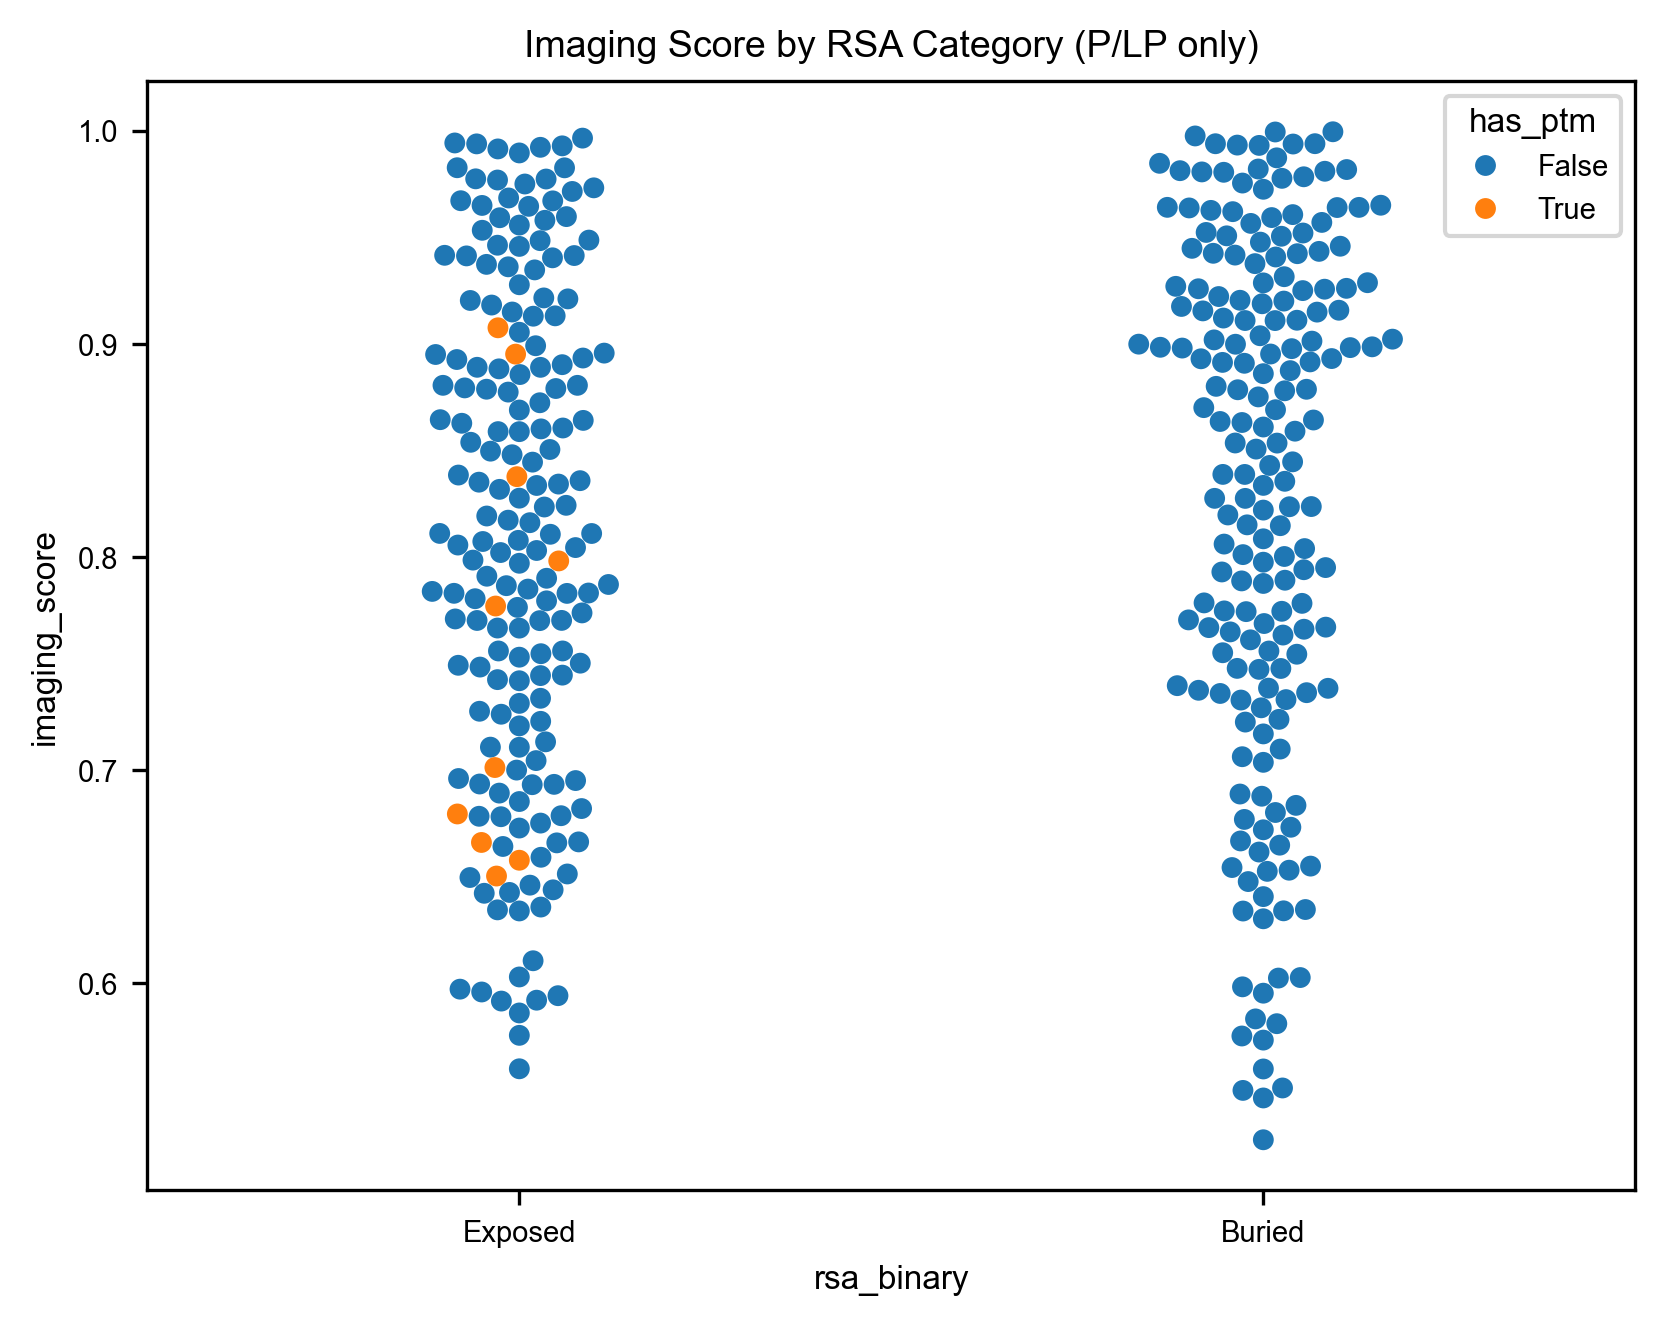

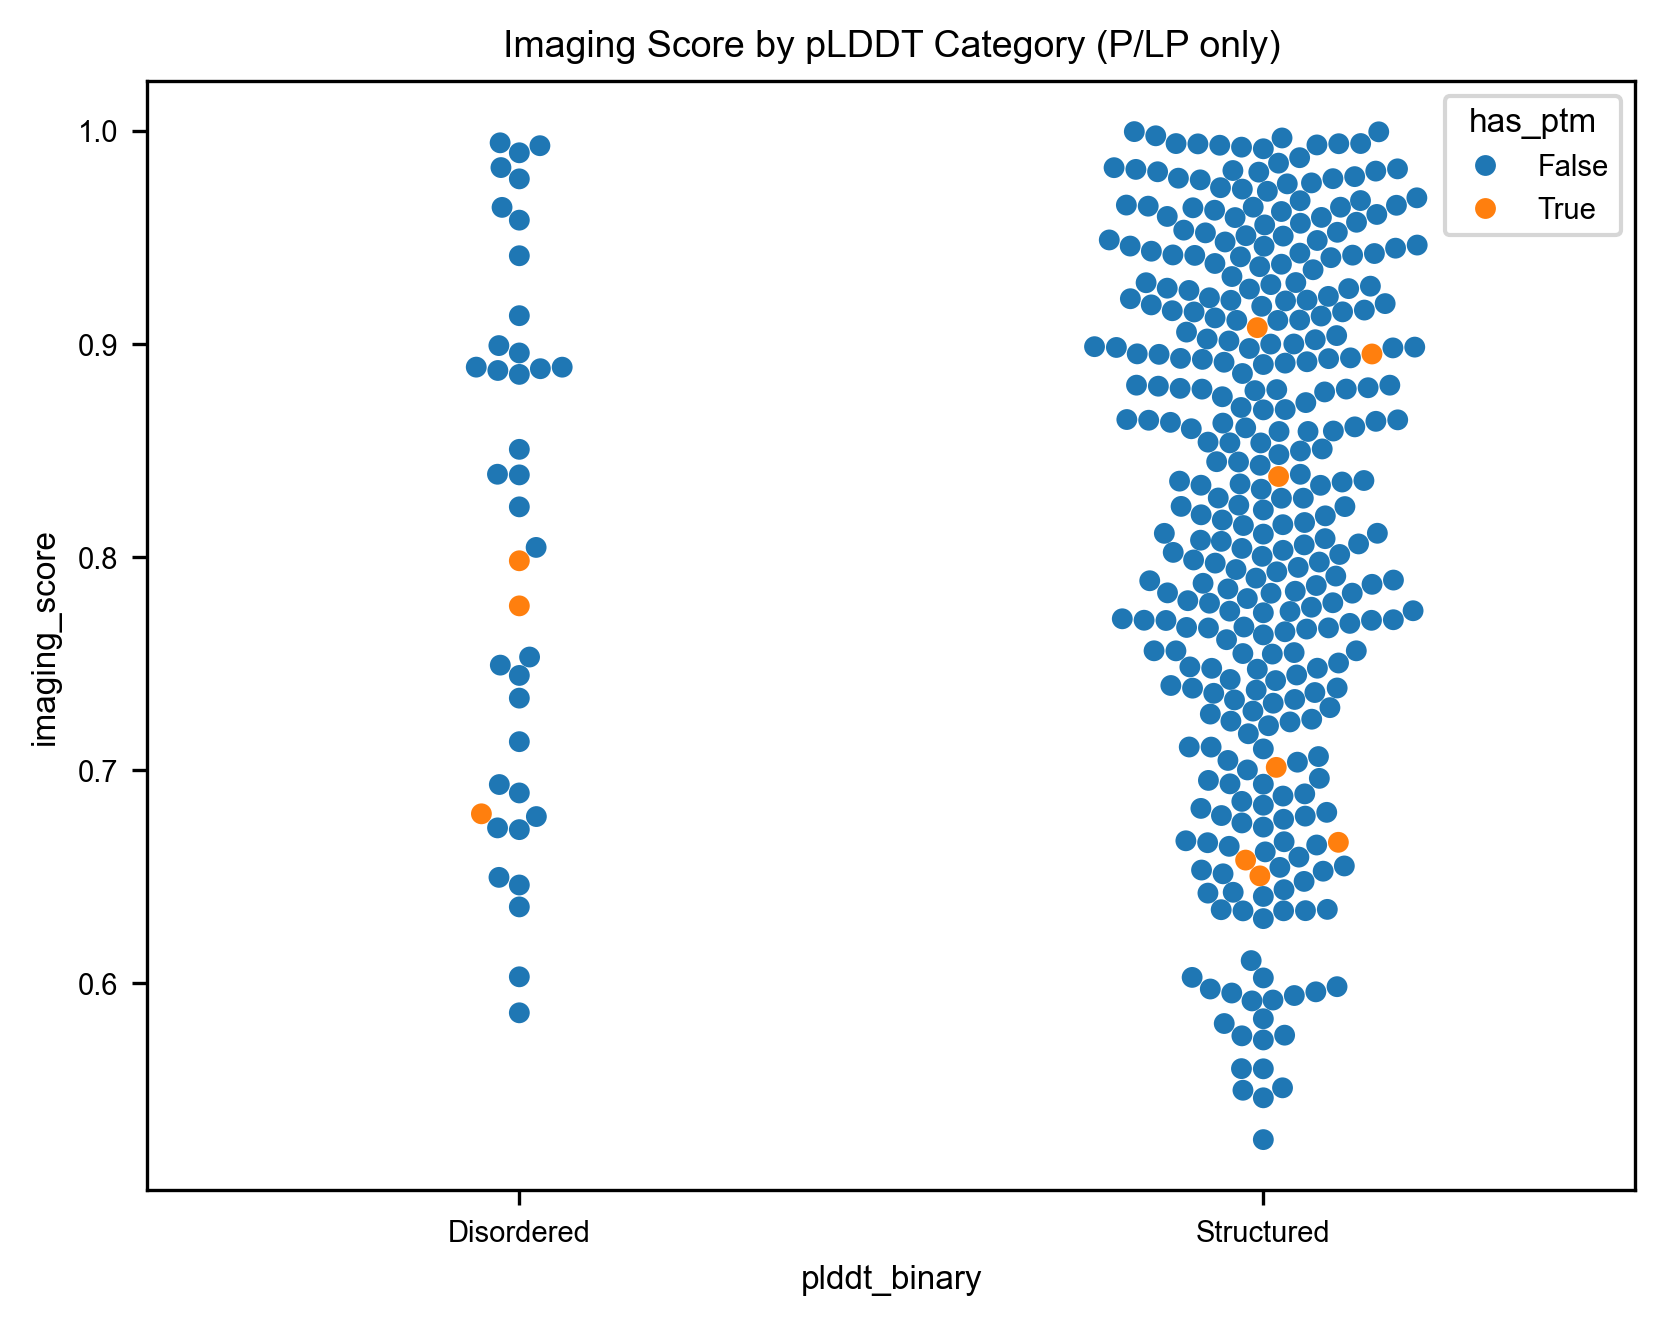

In [39]:
sns.swarmplot(data=df_plp_img_pd, x='rsa_binary', y='imaging_score',
            order=['Exposed', 'Buried'],
            hue="has_ptm",
            # cut=0,
            # gap=.1
            )
plt.title('Imaging Score by RSA Category (P/LP only)')
plt.show()

sns.swarmplot(data=df_plp_img_pd, x='plddt_binary', y='imaging_score',
            order=['Disordered', 'Structured'],
            hue="has_ptm",
            # cut=0,
            # gap=.1
            )
plt.title('Imaging Score by pLDDT Category (P/LP only)')
plt.show()

### Summary: Localization/Trafficking Features in Disordered/Exposed Regions

**Key Findings:**

1. **Composite Feature Definition**: We identified 14 G2P annotation categories relevant to protein localization and trafficking:
   - Targeting signals (signal peptide, transit peptide, NLS/NES motifs)
   - Membrane topology (transmembrane, topological domain, intramembrane)
   - PTMs (phosphorylation, ubiquitination, acetylation, methylation, glycosylation, modified residue)
   - Structural features (propeptide, coiled coil)

2. **Structural Enrichment Pattern**: Localization/trafficking-related annotations are significantly **enriched in exposed/disordered regions**:
   - These features often require surface accessibility for recognition by trafficking machinery
   - PTM sites (phosphorylation, ubiquitination) show particularly strong enrichment in flexible regions

3. **Mechanistic Explanation for Imaging's Structure-Independence**:
   - Pathogenic variants in disordered/exposed regions can disrupt localization through:
     - Loss of PTM sites (kinase recognition)
     - Disruption of NLS/NES motifs
     - Interference with signal peptide function
   - These mechanisms are **not captured by structural metrics** (RSA/pLDDT) alone
   - Imaging assay detects cellular phenotypes arising from these localization defects

4. **Assay Complementarity**:
   - **Dual-IPA**: Sensitive to stability defects (buried residues)
   - **PPI**: Sensitive to interface disruption (buried interface residues)
   - **Imaging**: Sensitive to localization/trafficking defects (accessible regulatory residues)
   - Together, these assays capture distinct pathogenic mechanisms

**References for Annotation Relevance:**
- Signal peptides: von Heijne, 1990; Emanuelsson et al., 2000
- PTM regulation: Nishi et al., 2014; Komander & Rape, 2012
- Nuclear localization: Lange et al., 2007
- Membrane topology: Krogh et al., 2001

### Scientific Interpretation: Imaging Provides Unique Sensitivity at Exposed Positions

Our multi-assay profiling reveals a critical asymmetry in how each assay detects pathogenic variants across structural contexts.

#### Key Finding: Assay Performance by Structural Category

When we examine each assay's ability to distinguish P/LP from B/LB **within each structural category**:

| Structural Context | Dual-IPA | Imaging | PPI |
|-------------------|----------|---------|-----|
| **Buried** | AUROC=0.83 ✓ | AUROC=0.69 ✓ | AUROC=0.76 ✓ |
| **Exposed** | AUROC=0.58 ✗ | **AUROC=0.67 ✓** | AUROC=0.44 ✗ |

#### Mechanistic Explanation

**Why Dual-IPA and PPI fail at exposed positions:**
- Dual-IPA measures protein abundance (stability). Exposed variants often don't destabilize the core → no signal.
- PPI measures interaction integrity. Exposed variants often don't disrupt buried interfaces → no signal.

**Why imaging maintains sensitivity everywhere:**
- Imaging captures **downstream cellular phenotypes** (morphology, localization) that integrate multiple upstream perturbations.
- Whether variants destabilize the core OR disrupt PTM sites OR interfere with trafficking signals → the cellular consequence is detectable.

#### Revised Understanding of Functional Annotations

Functional annotations (PTMs, trafficking signals) are enriched at exposed/disordered positions. This explains **why pathogenic variants exist there**—these are functional sites where sequence changes can cause disease without destabilizing the protein. However:

- Annotations do NOT directly predict higher imaging scores
- Rather, imaging detects pathogenic variants at these positions because it measures cellular consequences, not specific molecular mechanisms

#### Implications for Multi-Assay Strategy

| Assay | Strength | Limitation |
|-------|----------|------------|
| **Dual-IPA** | High sensitivity at buried positions | Fails at exposed positions |
| **PPI** | High sensitivity at interface residues | Fails at exposed positions |
| **Imaging** | Consistent sensitivity across ALL positions | Lower peak sensitivity |

**Conclusion:** Dual-IPA and PPI provide focused, high-sensitivity detection at structurally constrained positions, while imaging provides broad coverage across all structural contexts. Together, they achieve comprehensive variant detection that no single assay could provide.

---
## Panel F: Hit Rates by Secondary Structure

In [81]:
# Get secondary structure column
ss_col = 'g2p_Secondary structure (DSSP 3-state)*'

df_patho_ss = df.filter(
    (pl.col('clin_binary') == 'PLP') &
    pl.col(ss_col).is_not_null()
)

print(f"P/LP variants with secondary structure data: {len(df_patho_ss)}")
print(df_patho_ss[ss_col].value_counts())

# Panel F: Hit rates by secondary structure
ss_order = ['H (helix)', 'B (undefined)', 'C (loop/coil)']

fig, ax = plt.subplots(figsize=(5, 3))
# Compute hit rates
ss_results = []
for assay_name, hit_col in assay_hit_cols.items():
    for ss in ss_order:
        subset = df_patho_ss.filter(
            (pl.col(ss_col) == ss) &
            pl.col(hit_col).is_not_null()
        )
        n_total = subset.height
        n_hits = subset.filter(pl.col(hit_col)).height
        hit_rate = n_hits / n_total * 100 if n_total > 0 else 0
        
        ss_results.append({
            'Assay': assay_name,
            'Secondary Structure': ss,
            'Hit Rate (%)': hit_rate,
            'n': n_total
        })

ss_plot_df = pd.DataFrame(ss_results)

# Plot grouped bars
x = np.arange(len(ss_order))
width = 0.25
offsets = np.linspace(-width, width, len(assay_hit_cols))

for i, assay_name in enumerate(assay_order):
    assay_data = ss_plot_df[ss_plot_df['Assay'] == assay_name]
    rates = [assay_data[assay_data['Secondary Structure'] == ss]['Hit Rate (%)'].values[0] 
             for ss in ss_order]
    
    bars = ax.bar(
        x + offsets[i],
        rates,
        width * 0.9,
        label=assay_name,
        color=assay_palette[assay_name],
        edgecolor='black',
        linewidth=0.5
    )
    
    # Add labels
    for bar, rate in zip(bars, rates):
        if rate > 0:
            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_height() + 1,
                f'{rate:.1f}%',
                ha='center', va='bottom',
                fontsize=6, fontweight='bold'
            )

ax.set_xticks(x)
ax.set_xticklabels(['Helix', 'Strand/Undef.', 'Loop/Coil'])
ax.set_ylabel('Hit Rate (%)')
ax.set_title('Panel F: Hit Rate by Secondary Structure (P/LP)')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
fig.show()

# # Save
# fig.savefig(f'{OUTPUT_DIR}/figure2_panel_f.pdf', bbox_inches='tight', dpi=300)

P/LP variants with secondary structure data: 602
shape: (3, 2)
┌─────────────────────────────────┬───────┐
│ g2p_Secondary structure (DSSP … ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ B (undefined)                   ┆ 144   │
│ H (helix)                       ┆ 272   │
│ C (loop/coil)                   ┆ 186   │
└─────────────────────────────────┴───────┘


---
## Panel G: Disease Module Analysis

In [84]:
# Check disease modules
df_patho_disease = df.filter(
    (pl.col('clin_binary') == 'PLP') &
    pl.col('disease_modules').is_not_null()
)

print(f"P/LP variants with disease module data: {len(df_patho_disease)}")
print("\nSample disease modules:")
print(df_patho_disease['disease_modules'].head(10))

P/LP variants with disease module data: 662

Sample disease modules:
shape: (10,)
Series: 'disease_modules' [str]
[
	"Rare genetic developmental def…
	"Rare genetic developmental def…
	"Rare inborn errors of metaboli…
	"Rare inborn errors of metaboli…
	"Rare inborn errors of metaboli…
	"Rare inborn errors of metaboli…
	"Rare genetic eye disease; Rare…
	"Rare genetic eye disease; Rare…
	"Rare genetic eye disease; Rare…
	"Rare genetic eye disease; Rare…
]


In [85]:
# Parse disease modules and compute hit rates
module_stats = {}

for i in range(len(df_patho_disease)):
    row = df_patho_disease.row(i, named=True)
    modules = str(row['disease_modules']).split(';') if row['disease_modules'] else []
    
    for module in modules:
        module = module.strip()
        if not module:
            continue
            
        if module not in module_stats:
            module_stats[module] = {
                'total': 0,
                'Dual-IPA_tested': 0, 'Dual-IPA_hits': 0,
                'Imaging_tested': 0, 'Imaging_hits': 0,
                'PPI_tested': 0, 'PPI_hits': 0
            }
        
        module_stats[module]['total'] += 1
        
        for assay_name, hit_col in assay_hit_cols.items():
            if row[hit_col] is not None:
                module_stats[module][f'{assay_name}_tested'] += 1
                if row[hit_col]:
                    module_stats[module][f'{assay_name}_hits'] += 1

# Convert to DataFrame and filter
module_df = pd.DataFrame([
    {'Module': k, **v} for k, v in module_stats.items()
])

# Filter to modules with >= 5 variants
module_df_filtered = module_df[module_df['total'] >= 5].copy()

# Calculate hit fractions
for assay_name in assay_order:
    module_df_filtered[f'{assay_name}_frac'] = (
        module_df_filtered[f'{assay_name}_hits'] / 
        module_df_filtered[f'{assay_name}_tested'].replace(0, np.nan)
    )

print(f"Disease modules with >= 5 variants: {len(module_df_filtered)}")

Disease modules with >= 5 variants: 26


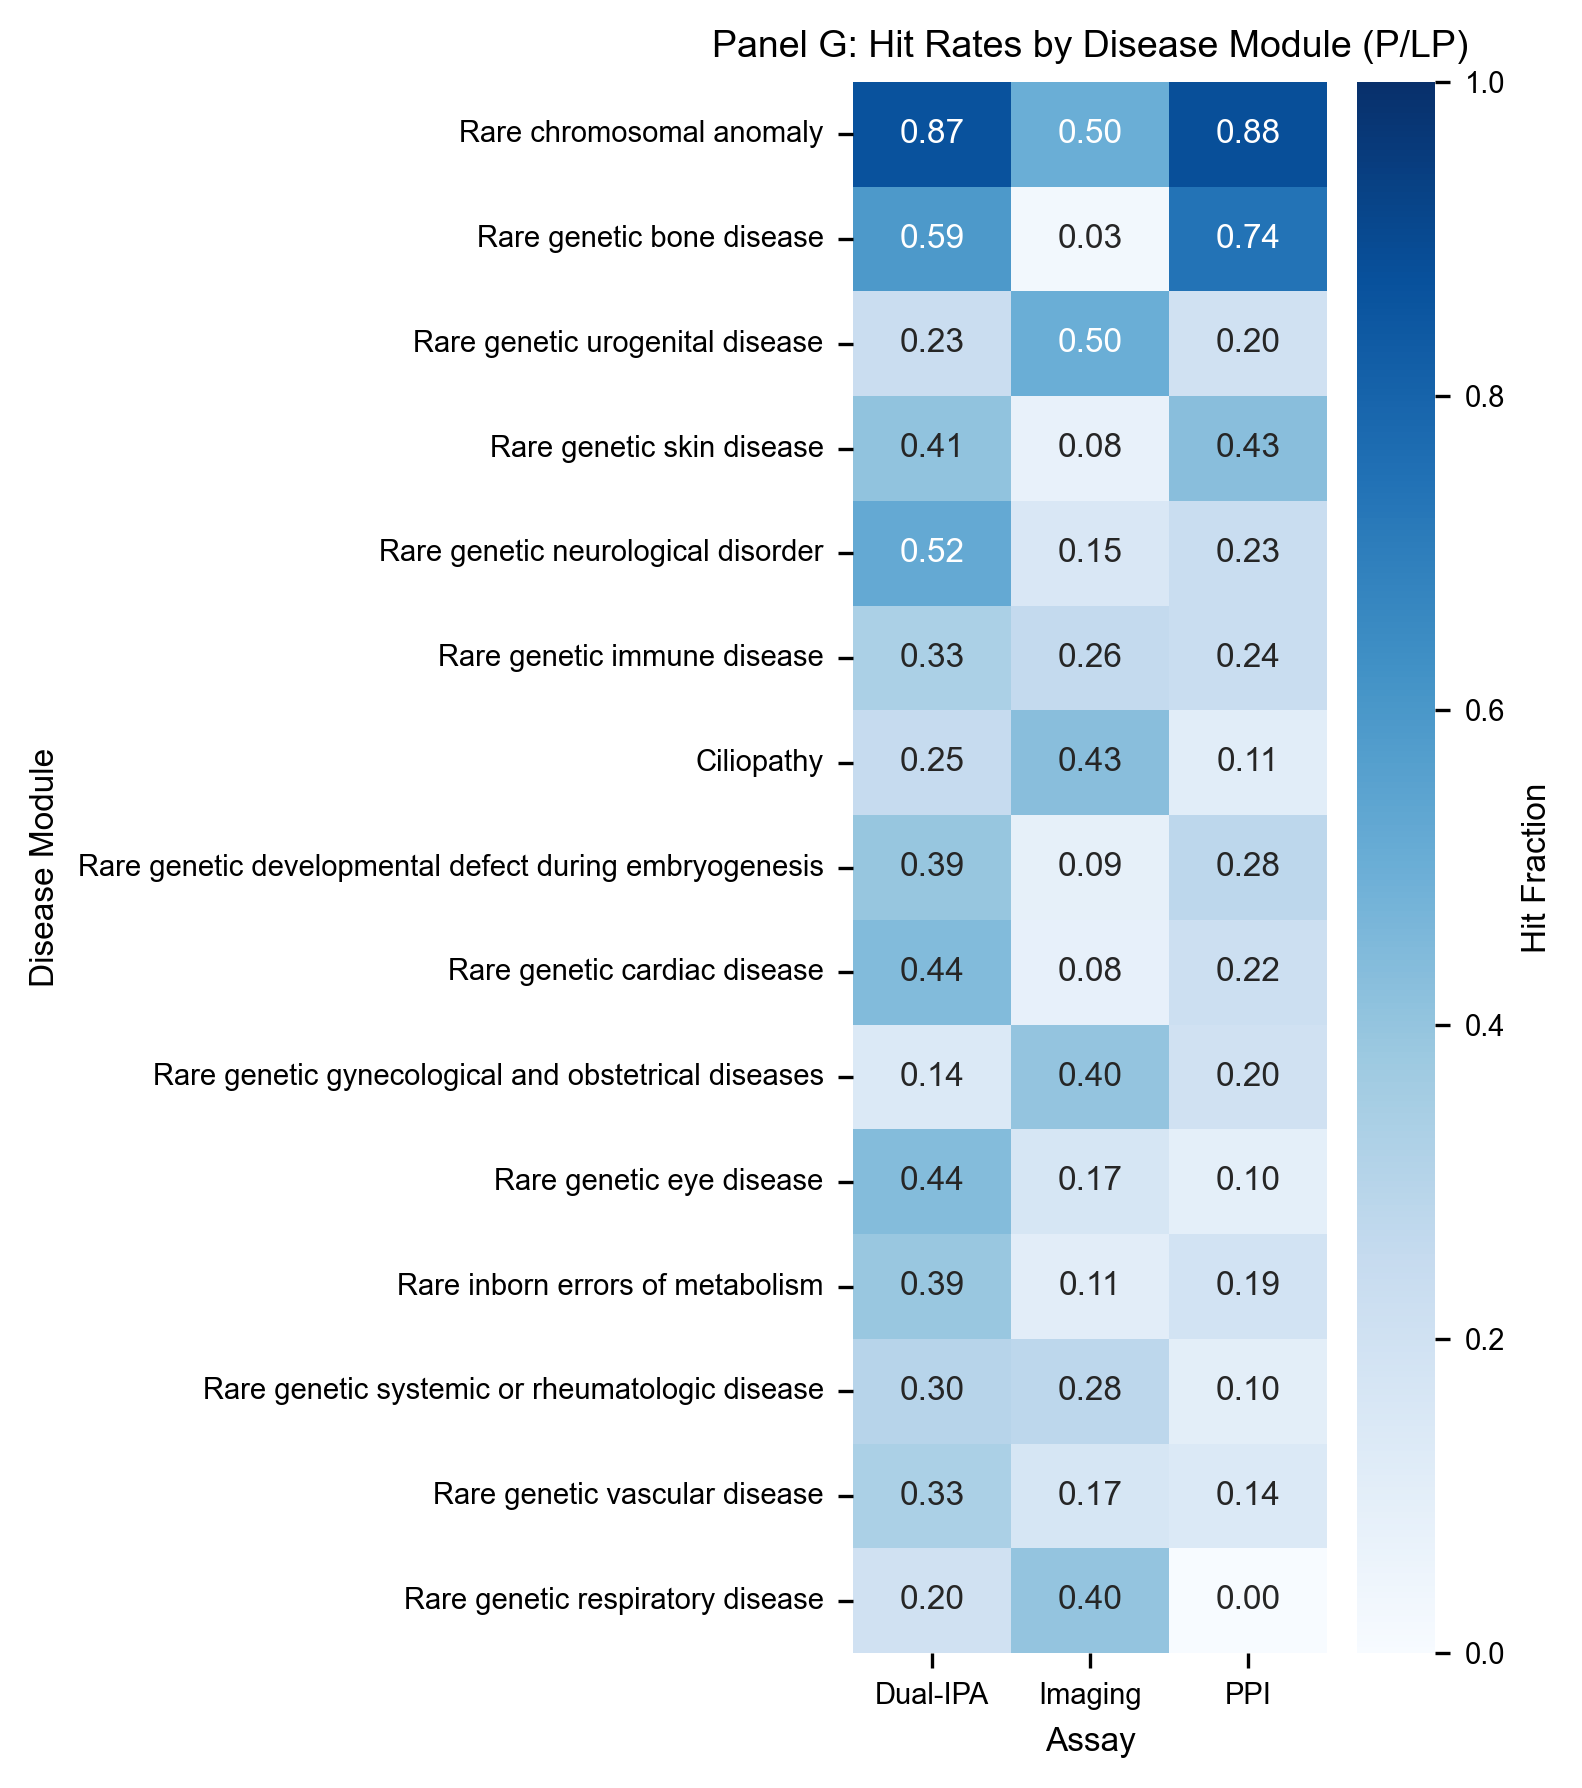

In [89]:
# Create heatmap for disease modules
if len(module_df_filtered) >= 3:
    heatmap_data = module_df_filtered.set_index('Module')[[
        'Dual-IPA_frac', 'Imaging_frac', 'PPI_frac'
    ]]
    heatmap_data.columns = ['Dual-IPA', 'Imaging', 'PPI']
    
    # Sort by mean hit fraction
    heatmap_data['mean'] = heatmap_data.mean(axis=1)
    heatmap_data = heatmap_data.sort_values('mean', ascending=False).drop('mean', axis=1)
    heatmap_data = heatmap_data.head(15)  # Top 15 modules
    
    fig, ax = plt.subplots(figsize=(5, 6))
    sns.heatmap(
        heatmap_data,
        cmap='Blues',
        vmin=0, vmax=1,
        annot=True,
        fmt='.2f',
        ax=ax,
        cbar_kws={'label': 'Hit Fraction'}
    )
    ax.set_title('Panel G: Hit Rates by Disease Module (P/LP)')
    ax.set_xlabel('Assay')
    ax.set_ylabel('Disease Module')
    plt.tight_layout()
    plt.show()
    
    # # Save
    # fig.savefig(f'{OUTPUT_DIR}/figure2_panel_g.pdf', bbox_inches='tight', dpi=300)
else:
    print("Insufficient disease modules for heatmap.")

---
## Panel H: Inheritance Mode Patterns

In [90]:
# Filter to pathogenic variants with inheritance data
df_patho_inh = df.filter(
    (pl.col('clin_binary') == 'PLP') &
    pl.col('inheritance_simple').is_not_null()
)

print(f"P/LP variants with inheritance data: {len(df_patho_inh)}")
print(df_patho_inh['inheritance_simple'].value_counts())

P/LP variants with inheritance data: 566
shape: (4, 2)
┌────────────────────┬───────┐
│ inheritance_simple ┆ count │
│ ---                ┆ ---   │
│ str                ┆ u32   │
╞════════════════════╪═══════╡
│ X-linked           ┆ 100   │
│ Dominant           ┆ 216   │
│ Recessive          ┆ 178   │
│ Multiple           ┆ 72    │
└────────────────────┴───────┘


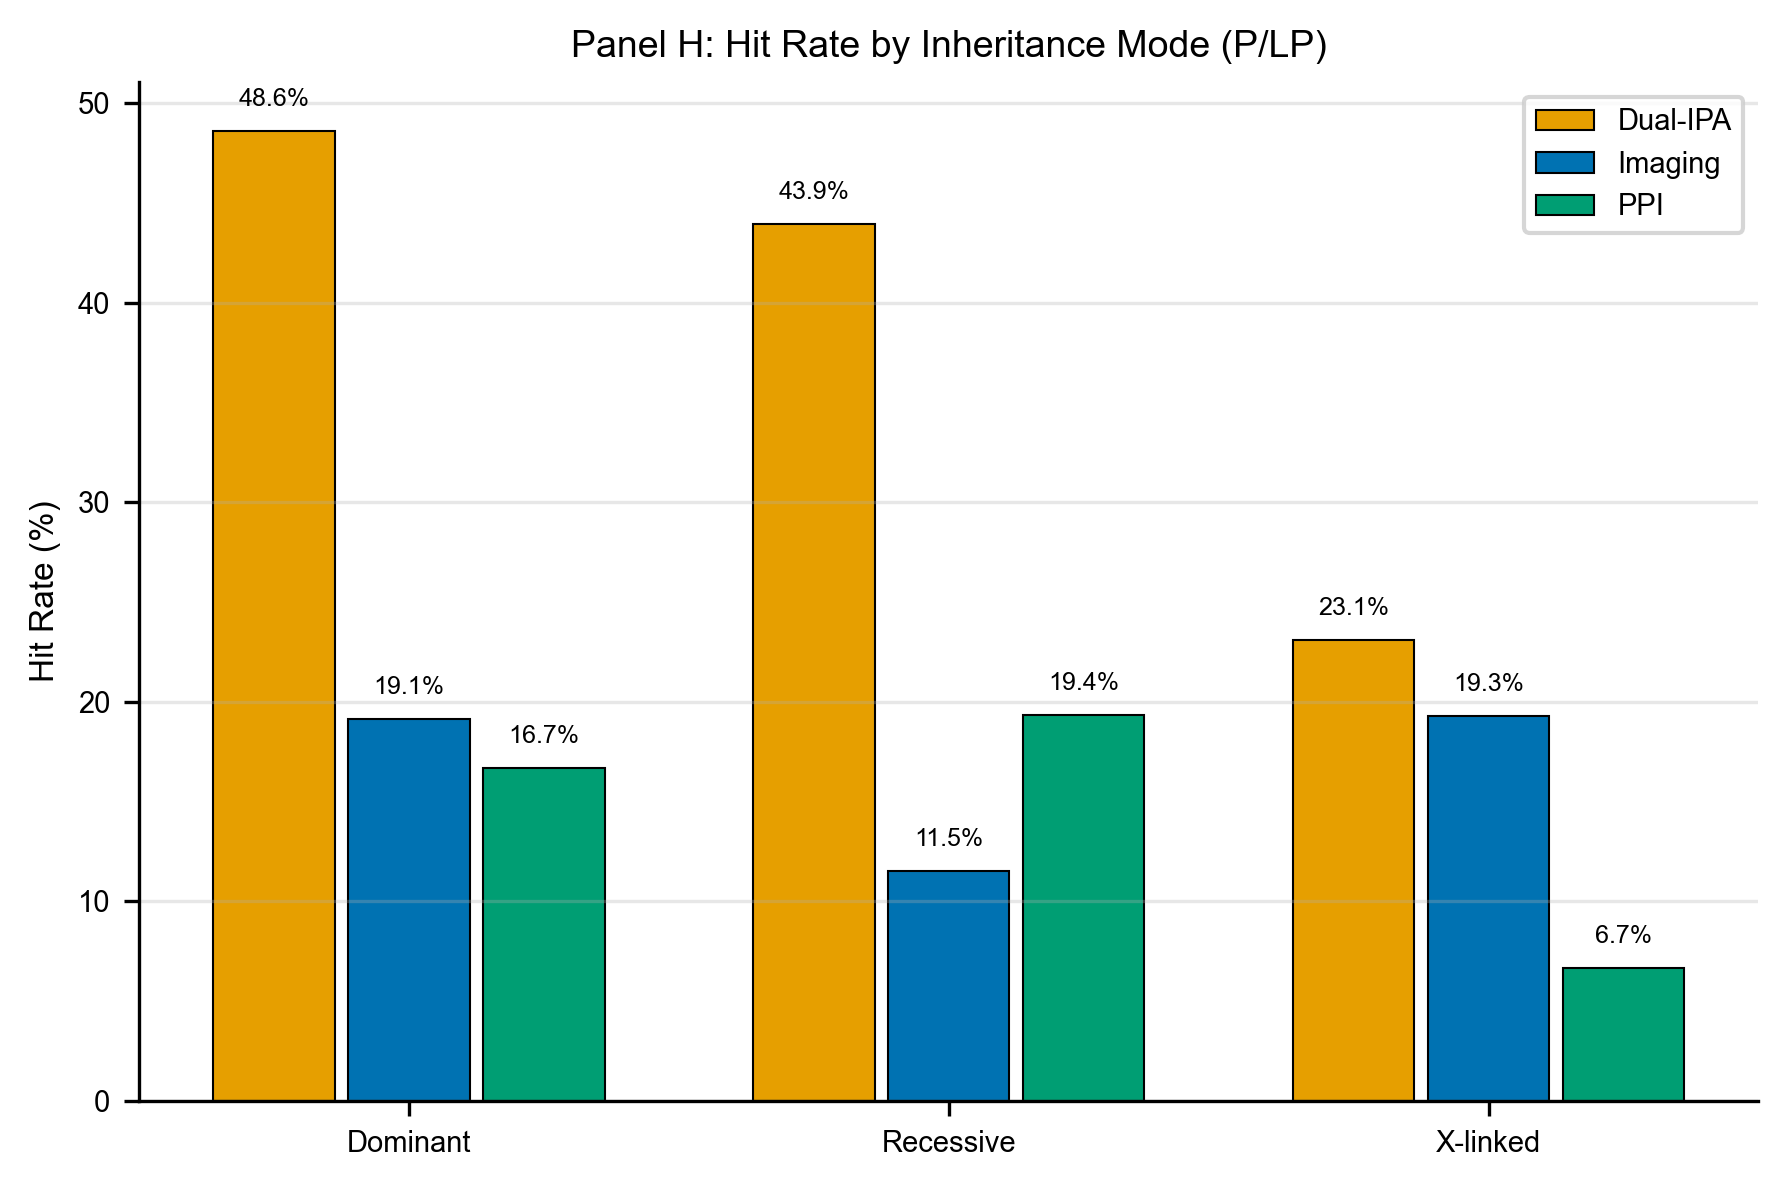

In [91]:
# Panel H: Hit rates by inheritance pattern
inh_order = ['Dominant', 'Recessive', 'X-linked']

fig, ax = plt.subplots(figsize=(6, 4))

# Compute hit rates
inh_results = []
for assay_name, hit_col in assay_hit_cols.items():
    for inh in inh_order:
        subset = df_patho_inh.filter(
            (pl.col('inheritance_simple') == inh) &
            pl.col(hit_col).is_not_null()
        )
        n_total = subset.height
        n_hits = subset.filter(pl.col(hit_col)).height
        hit_rate = n_hits / n_total * 100 if n_total > 0 else 0
        
        inh_results.append({
            'Assay': assay_name,
            'Inheritance': inh,
            'Hit Rate (%)': hit_rate,
            'n': n_total
        })

inh_plot_df = pd.DataFrame(inh_results)

# Plot grouped bars
x = np.arange(len(inh_order))
width = 0.25
offsets = np.linspace(-width, width, len(assay_hit_cols))

for i, assay_name in enumerate(assay_order):
    assay_data = inh_plot_df[inh_plot_df['Assay'] == assay_name]
    rates = []
    for inh in inh_order:
        rate_data = assay_data[assay_data['Inheritance'] == inh]['Hit Rate (%)']
        rates.append(rate_data.values[0] if len(rate_data) > 0 else 0)
    
    bars = ax.bar(
        x + offsets[i],
        rates,
        width * 0.9,
        label=assay_name,
        color=assay_palette[assay_name],
        edgecolor='black',
        linewidth=0.5
    )
    
    # Add labels
    for bar, rate in zip(bars, rates):
        if rate > 0:
            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_height() + 1,
                f'{rate:.1f}%',
                ha='center', va='bottom',
                fontsize=6, fontweight='bold'
            )

ax.set_xticks(x)
ax.set_xticklabels(inh_order)
ax.set_ylabel('Hit Rate (%)')
ax.set_title('Panel H: Hit Rate by Inheritance Mode (P/LP)')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
display(fig)
plt.close(fig)

# # Save
# fig.savefig(f'{OUTPUT_DIR}/figure2_panel_h.pdf', bbox_inches='tight', dpi=300)

---
## Panel I: Within-Gene Mechanistic Heterogeneity

In [92]:
# Extract protein position from aa_change
def extract_position(aa):
    if aa is None:
        return None
    match = re.search(r'(\d+)', str(aa))
    return int(match.group(1)) if match else None

df_patho_pos = df.filter(pl.col('clin_binary') == 'PLP').with_columns(
    pl.col('aa_change').map_elements(extract_position, return_dtype=pl.Int64).alias('aa_pos')
)

# Find genes with >= 5 pathogenic variants and hits in multiple assays
gene_heterogeneity = []

for gene in df_patho_pos['symbol'].unique().to_list():
    gene_df = df_patho_pos.filter(pl.col('symbol') == gene)
    
    if gene_df.height < 5:
        continue
    
    # Count hits per assay
    assays_with_hits = 0
    for hit_col in assay_hit_cols.values():
        if gene_df.filter(pl.col(hit_col) == True).height > 0:
            assays_with_hits += 1
    
    if assays_with_hits >= 2:
        gene_heterogeneity.append({
            'gene': gene,
            'n_variants': gene_df.height,
            'assays_with_hits': assays_with_hits
        })

heterogeneity_df = pd.DataFrame(gene_heterogeneity).sort_values(
    ['assays_with_hits', 'n_variants'], ascending=[False, False]
)

print(f"Genes with heterogeneous mechanisms: {len(heterogeneity_df)}")
print(heterogeneity_df.head(10))

Genes with heterogeneous mechanisms: 13
      gene  n_variants  assays_with_hits
2      MVK          15                 3
11   SMAD3          13                 3
3    NR0B1           5                 3
4     FBP1           5                 3
0     AGXT          59                 2
6      DCX          26                 2
7   STXBP1          23                 2
12   KCNJ2          21                 2
9     PLP1          11                 2
1     GFAP           7                 2


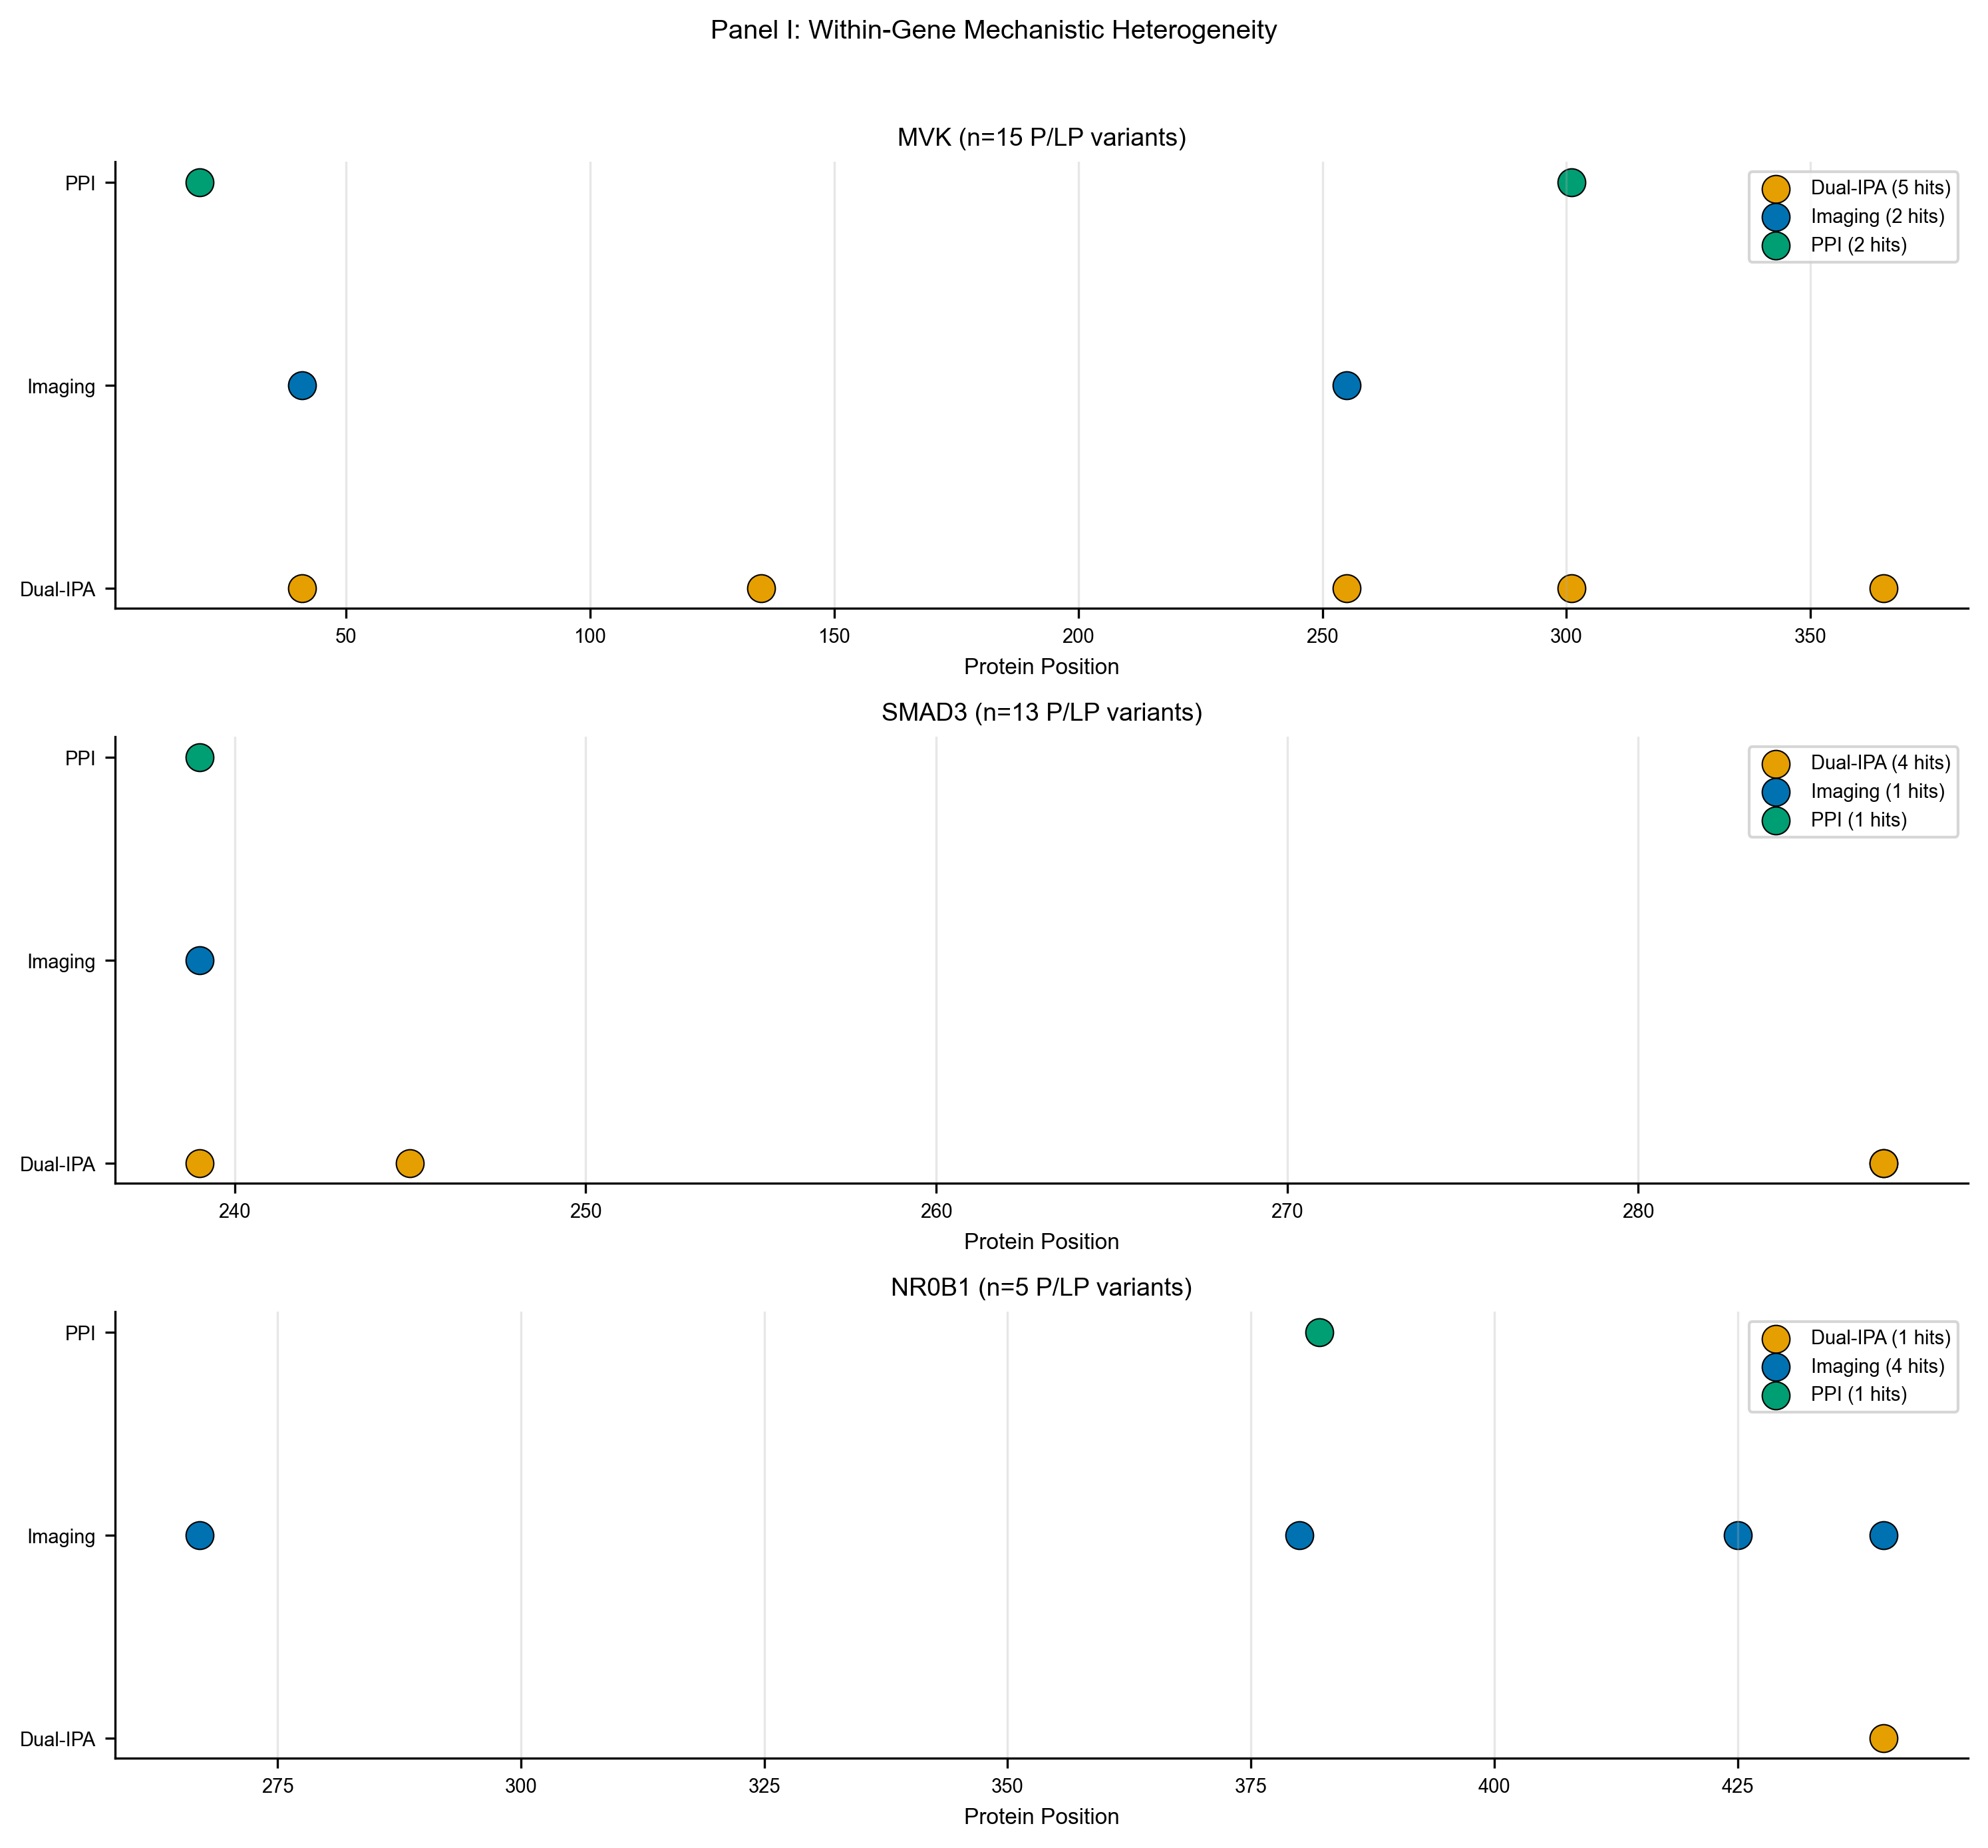

In [94]:
# Select top 3 genes for detailed visualization
selected_genes = heterogeneity_df.head(3)['gene'].tolist()

if len(selected_genes) >= 1:
    fig, axes = plt.subplots(len(selected_genes), 1, figsize=(10, 3 * len(selected_genes)))
    if len(selected_genes) == 1:
        axes = [axes]
    
    for idx, gene in enumerate(selected_genes):
        ax = axes[idx]
        gene_df = df_patho_pos.filter(pl.col('symbol') == gene).to_pandas()
        
        # Plot variants by position, colored by which assay detected them
        positions = gene_df['aa_pos'].dropna().values
        
        y_offset = 0
        for assay_name, hit_col in assay_hit_cols.items():
            hit_positions = gene_df[gene_df[hit_col] == True]['aa_pos'].dropna().values
            
            if len(hit_positions) > 0:
                ax.scatter(
                    hit_positions,
                    [y_offset] * len(hit_positions),
                    c=assay_palette[assay_name],
                    s=100,
                    label=f'{assay_name} ({len(hit_positions)} hits)',
                    marker='o',
                    edgecolor='black',
                    linewidth=0.5
                )
            y_offset += 1
        
        ax.set_yticks(range(len(assay_hit_cols)))
        ax.set_yticklabels(list(assay_hit_cols.keys()))
        ax.set_xlabel('Protein Position')
        ax.set_title(f'{gene} (n={len(gene_df)} P/LP variants)')
        ax.legend(loc='upper right', fontsize=7)
        ax.grid(axis='x', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    fig.suptitle('Panel I: Within-Gene Mechanistic Heterogeneity', y=1.02)
    plt.tight_layout()
    display(fig)
    plt.close(fig)
    
    # # Save
    # fig.savefig(f'{OUTPUT_DIR}/figure2_panel_i.pdf', bbox_inches='tight', dpi=300)
else:
    print("Insufficient genes for heterogeneity analysis.")

---
## Statistics Summary

In [ ]:
# Compile all statistics into a summary table
stats_summary = []

# Panel A stats
for assay, stats in panel_a_stats.items():
    if stats:
        stats_summary.append({
            'Panel': 'A',
            'Comparison': 'P/LP vs B/LB',
            'Assay': assay,
            'Test': 'Mann-Whitney U',
            'Statistic': stats['U_statistic'],
            'p_value': stats['p_value'],
            'Effect_size': stats['effect_size_r']
        })

# Panel D1 stats (RSA Fisher)
for assay, stats in rsa_stats_fisher.items():
    stats_summary.append({
        'Panel': 'D1',
        'Comparison': 'Buried vs Exposed (RSA)',
        'Assay': assay,
        'Test': "Fisher's exact",
        'Statistic': stats['odds_ratio'],
        'p_value': stats['p_value'],
        'Effect_size': None
    })

# Panel D2 stats (RSA Mann-Whitney)
for assay, stats in rsa_stats_mw.items():
    if stats:
        stats_summary.append({
            'Panel': 'D2',
            'Comparison': 'Buried vs Exposed (RSA)',
            'Assay': assay,
            'Test': 'Mann-Whitney U',
            'Statistic': stats['U_statistic'],
            'p_value': stats['p_value'],
            'Effect_size': stats['effect_size_r']
        })

# Panel E1 stats (pLDDT Fisher)
for assay, stats in plddt_stats_fisher.items():
    stats_summary.append({
        'Panel': 'E1',
        'Comparison': 'Disordered vs Structured (pLDDT)',
        'Assay': assay,
        'Test': "Fisher's exact",
        'Statistic': stats['odds_ratio'],
        'p_value': stats['p_value'],
        'Effect_size': None
    })

# Panel E2 stats (pLDDT Mann-Whitney)
for assay, stats in plddt_stats_mw.items():
    if stats:
        stats_summary.append({
            'Panel': 'E2',
            'Comparison': 'Disordered vs Structured (pLDDT)',
            'Assay': assay,
            'Test': 'Mann-Whitney U',
            'Statistic': stats['U_statistic'],
            'p_value': stats['p_value'],
            'Effect_size': stats['effect_size_r']
        })

stats_df = pd.DataFrame(stats_summary)
print(stats_df.to_string())

# # Save statistics
# stats_df.to_csv(f'{OUTPUT_DIR}/figure2_stats_summary.tsv', sep='\t', index=False)

---
## Summary

The notebook has been reorganized with improved logical flow for the structural context analysis.

### Panels Generated:
- **A**: Score distributions (P/LP vs B/LB) - Mann-Whitney U test
- **B**: Assay orthogonality (UpSet plot)

### Structural Context Analysis (NEW ORGANIZATION):
1. Unbiased overall view (P/LP + B/LB combined)
2. P/LP-focused comparison showing assay-specific differences
3. Functional feature analysis (PTM, signal peptides, localization)
4. Biological interpretation

### Additional Stratifications:
- **F**: Secondary structure hit rates
- **G**: Disease module heatmap
- **H**: Inheritance mode patterns
- **I**: Within-gene heterogeneity

### Key Findings:
- **Overall**: All assays show higher scores in buried/structured regions
- **Within P/LP**: Imaging LOSES structural sensitivity; Dual-IPA and PPI retain it
- **Mechanism**: PTM sites enriched in disordered/exposed regions explain imaging's structure-independence
- **Conclusion**: Imaging captures complementary information beyond protein destabilization